All potential strategies detected: ['Open Borders', 'Short Quarantine', 'Long Quarantine', 'Negative Test', 'VIP Only']
Strategy mapping created: {'OpenBorders': 'Open Borders', 'ShortQuarantine': 'Short Quarantine', 'LongQuarantine': 'Long Quarantine', 'NegativeTest': 'Negative Test', 'VIPOnly': 'VIP Only'}
Peak summary extracted. Total peaks found: 236
Found 3 Travel Rates and 4 Pair Configurations.

=== Processing: Rate 0.00091 | Pair OpenBorders_vs_LongQuarantine ===


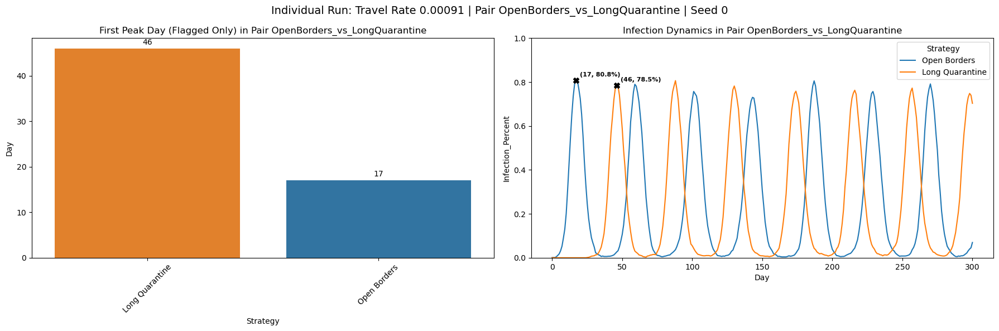

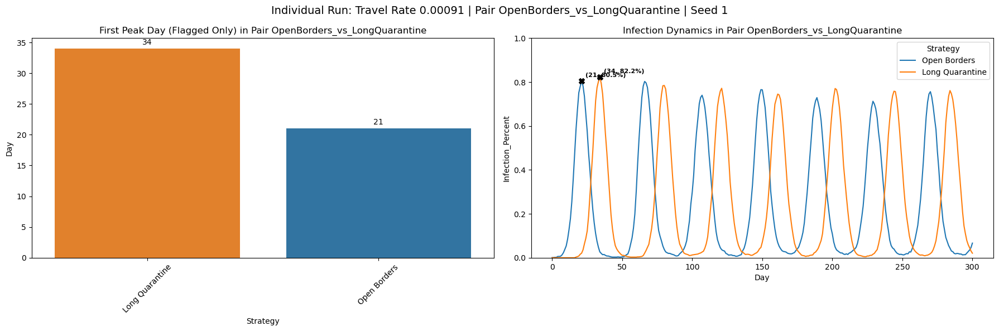

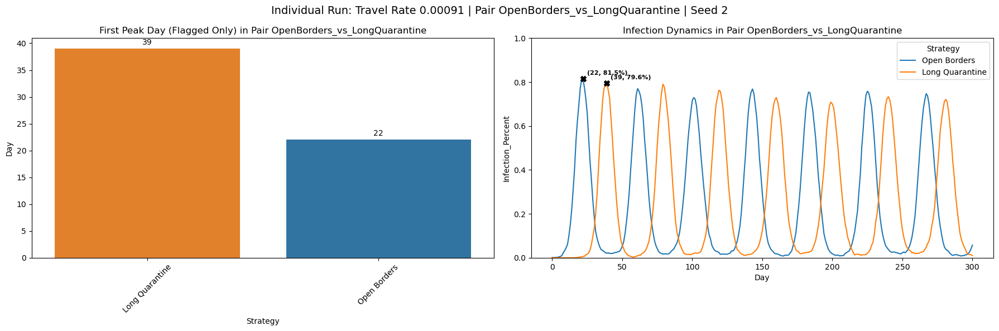

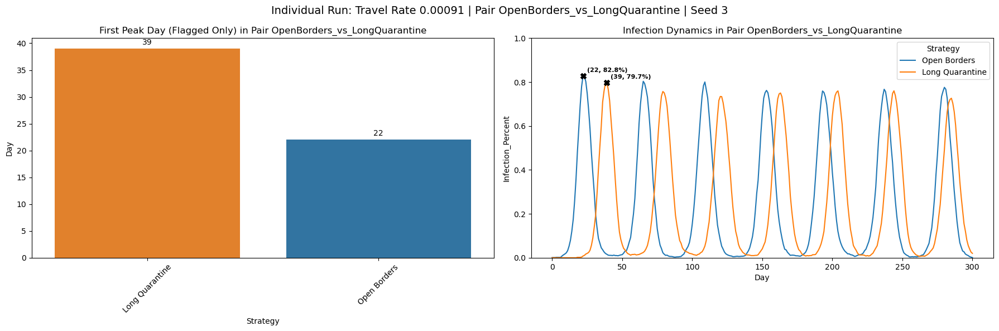

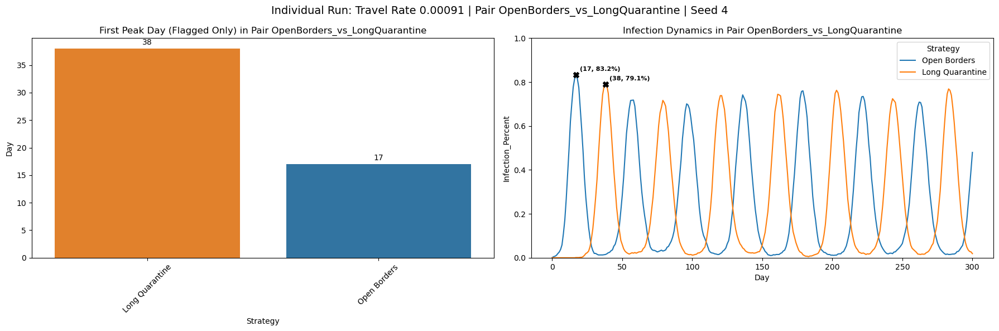

...

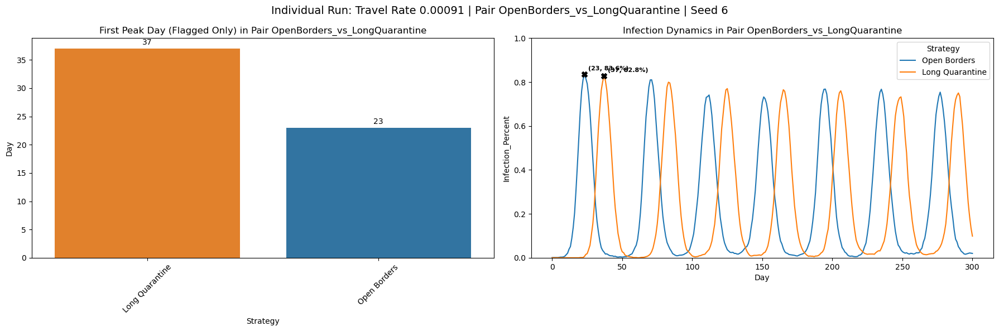

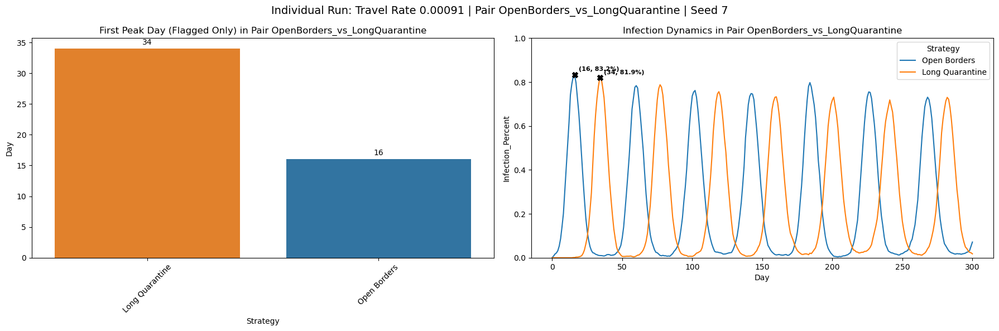

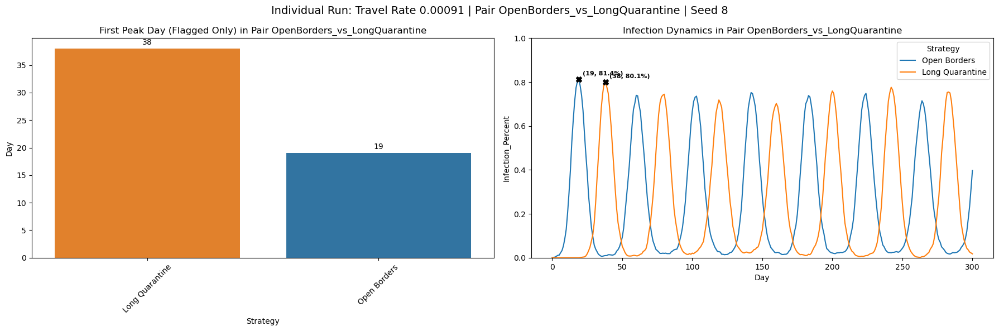

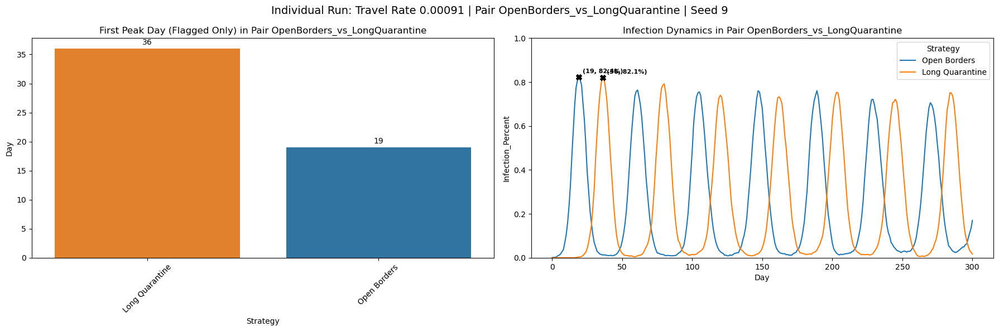

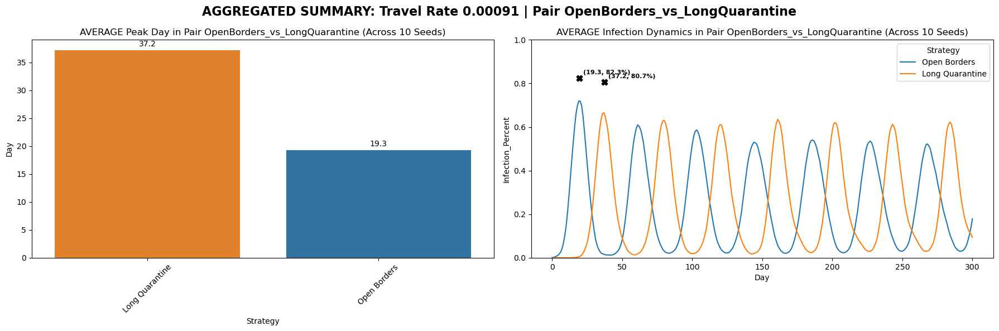


=== Processing: Rate 0.00091 | Pair OpenBorders_vs_NegativeTest ===


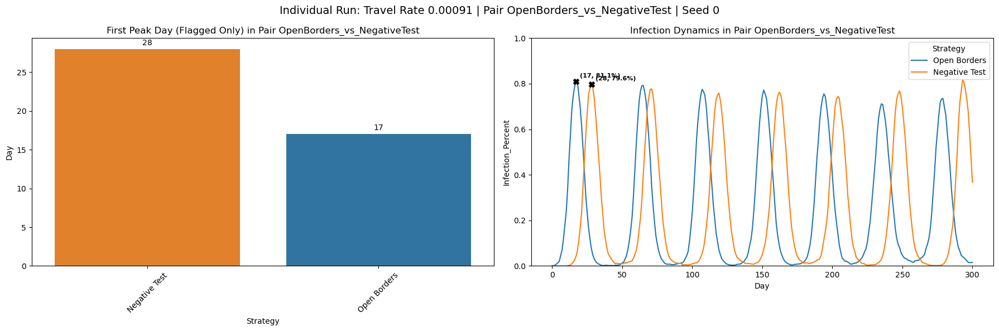

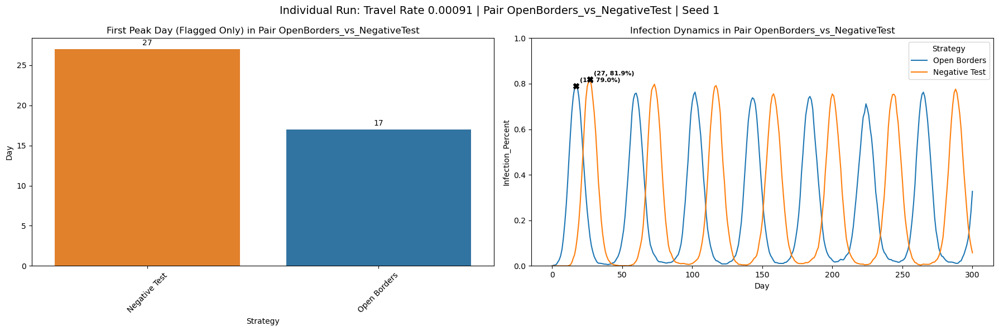

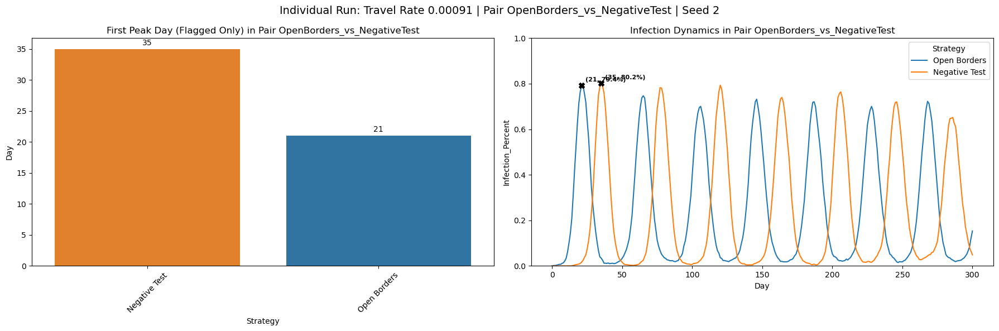

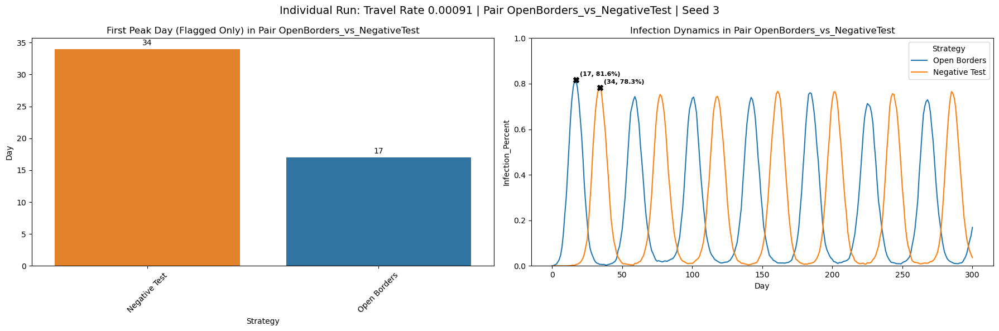

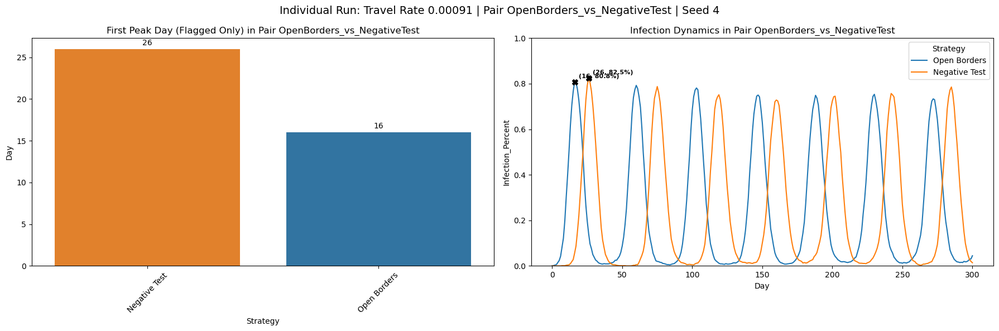

...

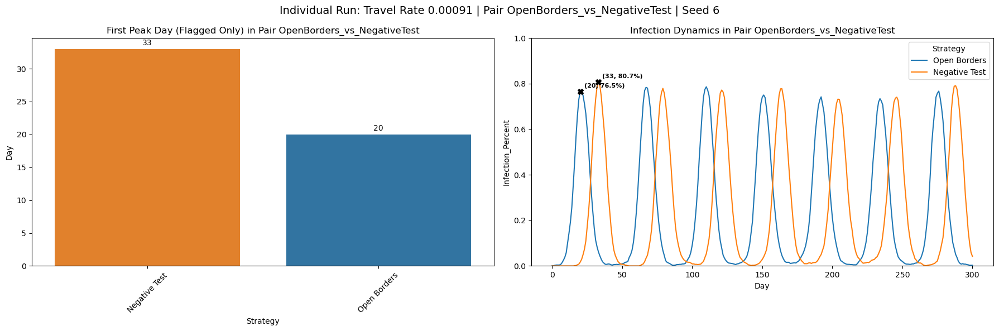

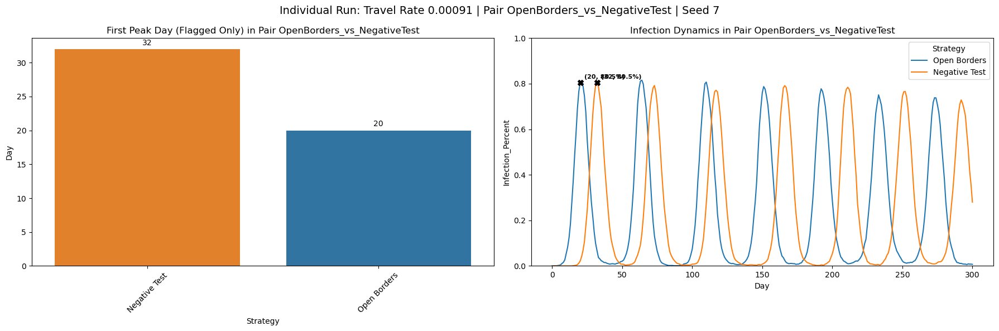

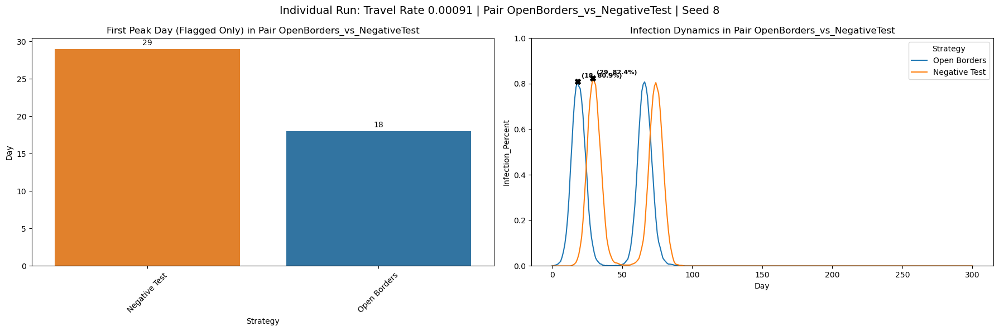

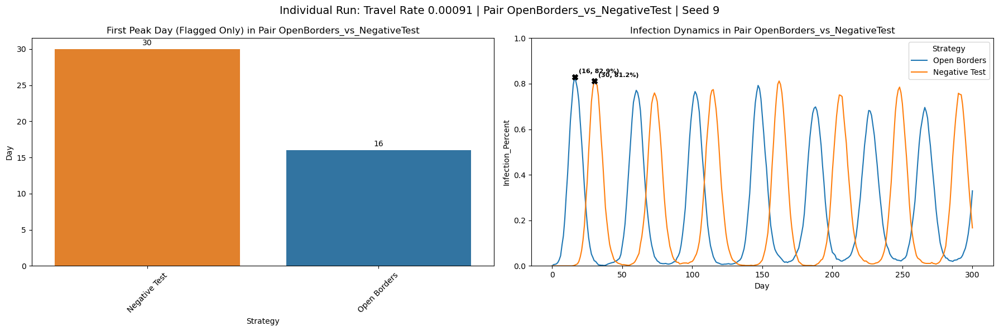

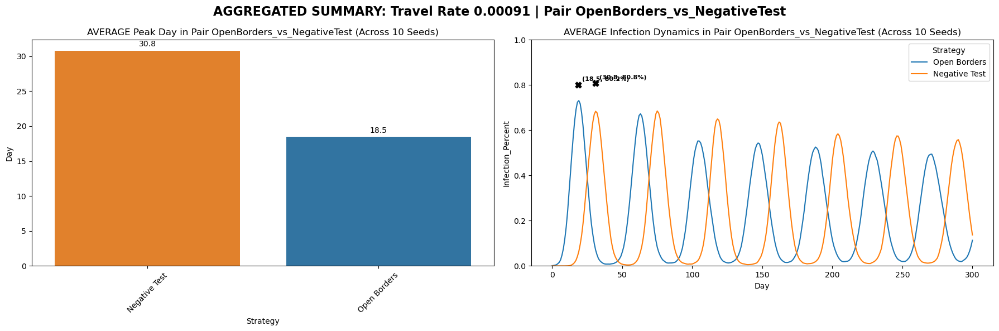


=== Processing: Rate 0.00091 | Pair OpenBorders_vs_ShortQuarantine ===


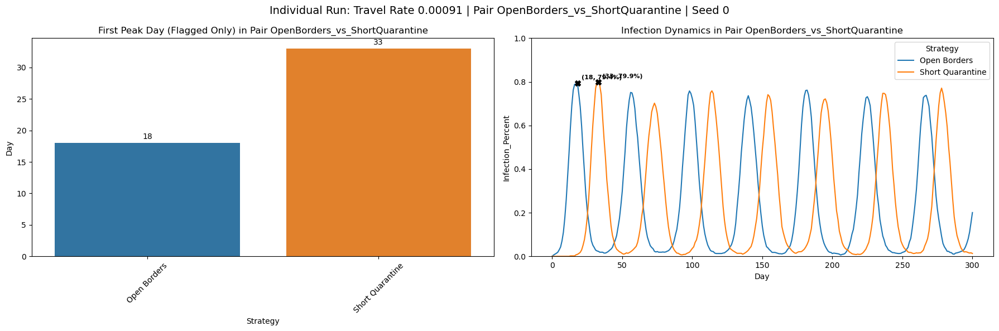

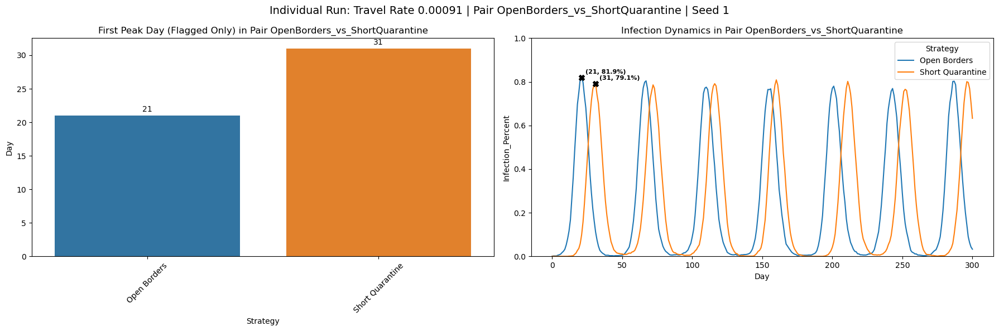

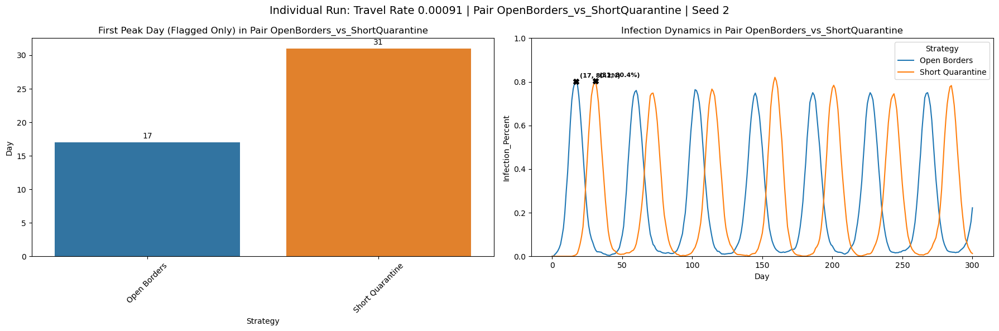

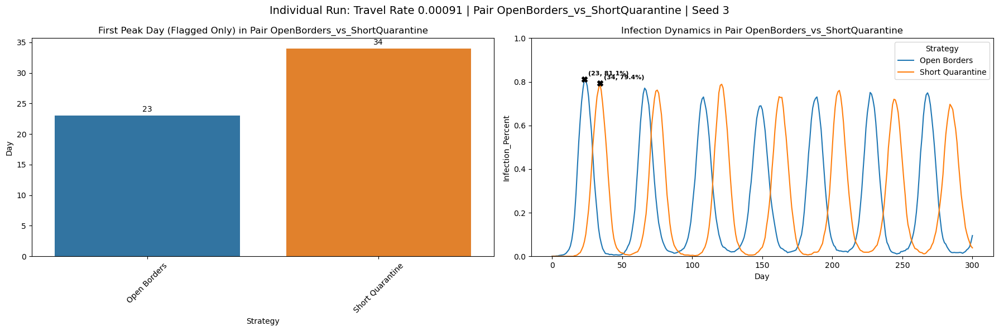

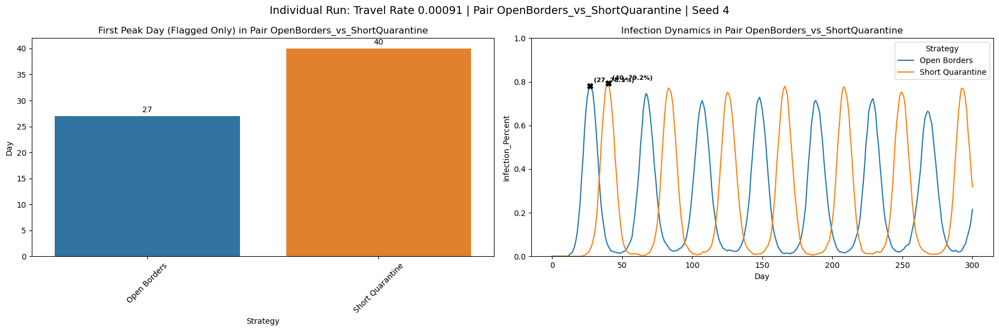

...

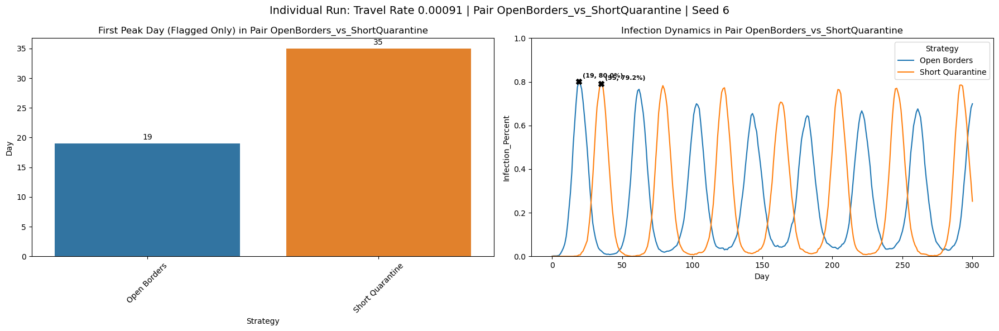

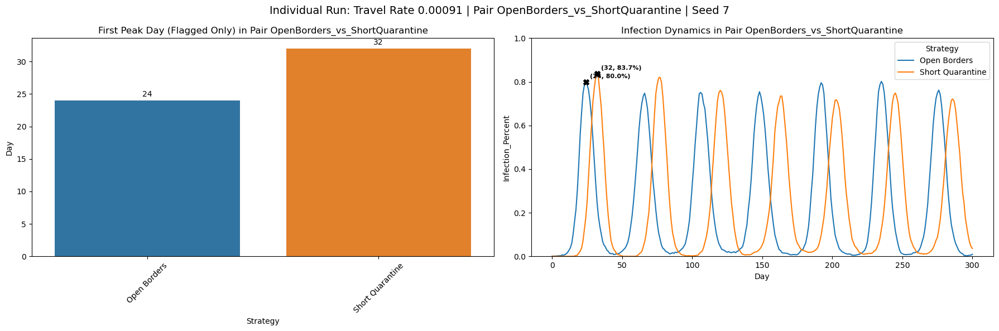

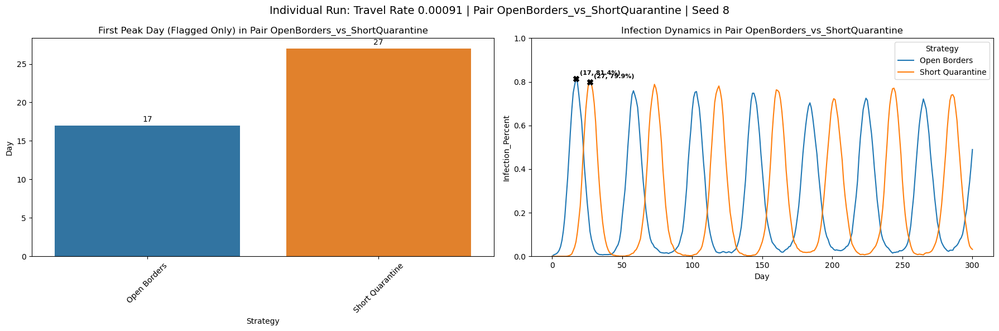

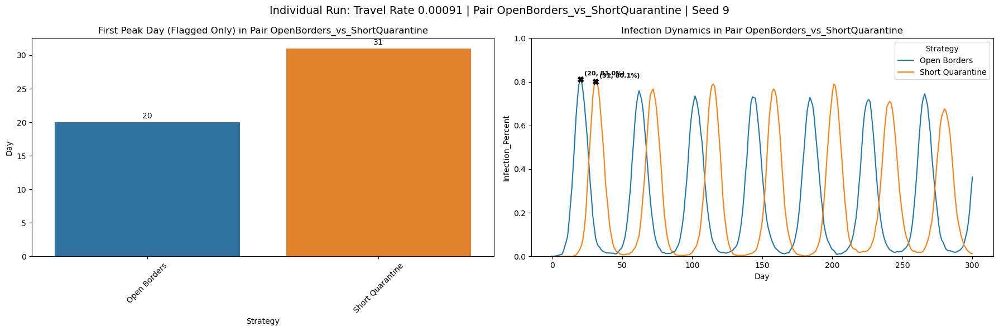

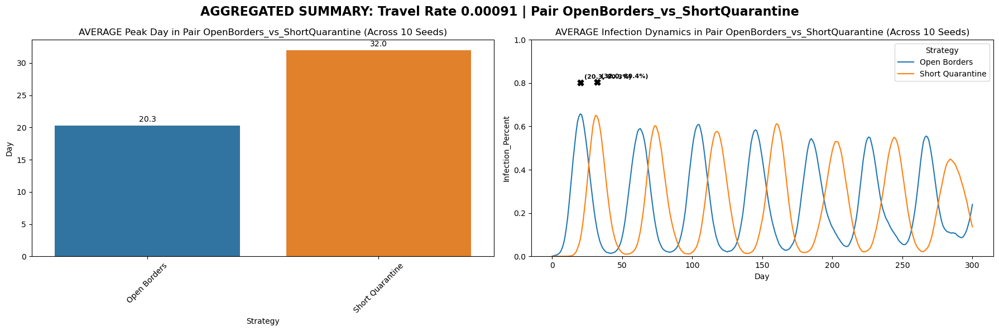


=== Processing: Rate 0.00091 | Pair OpenBorders_vs_VIPOnly ===


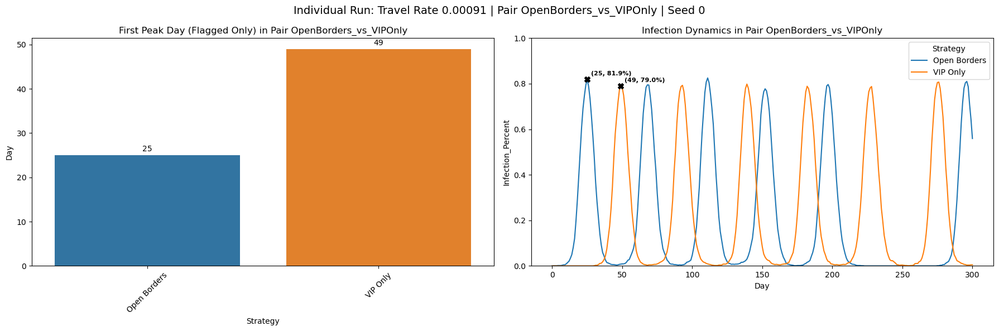

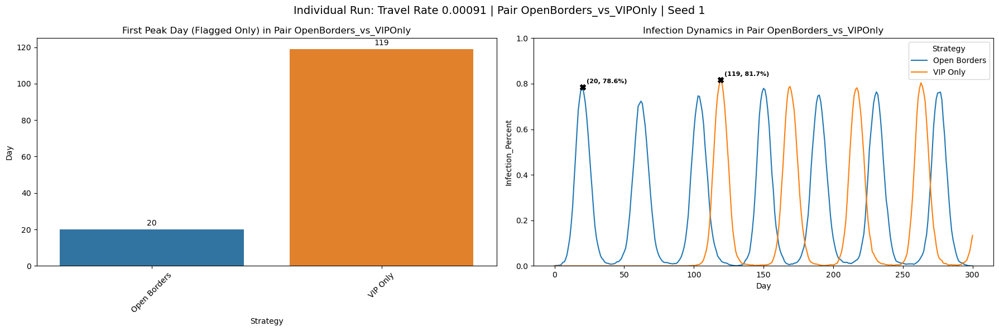

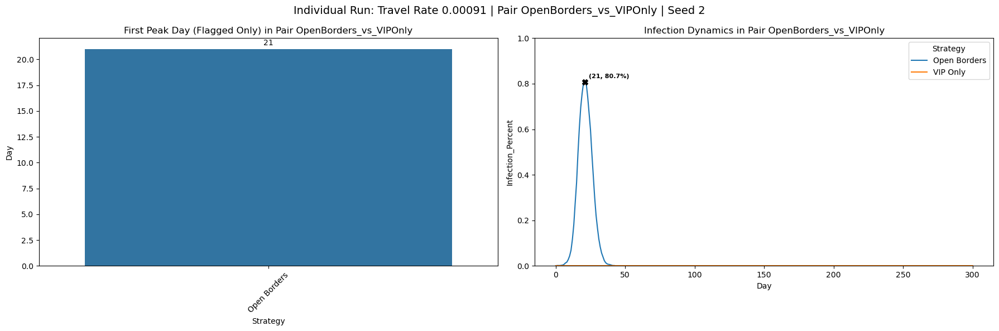

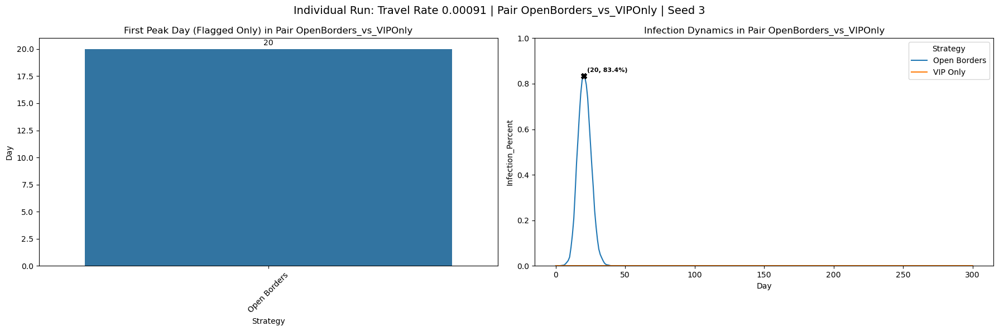

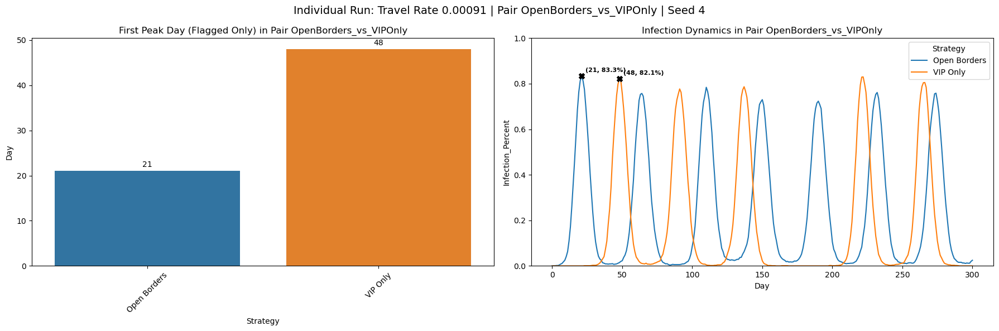

...

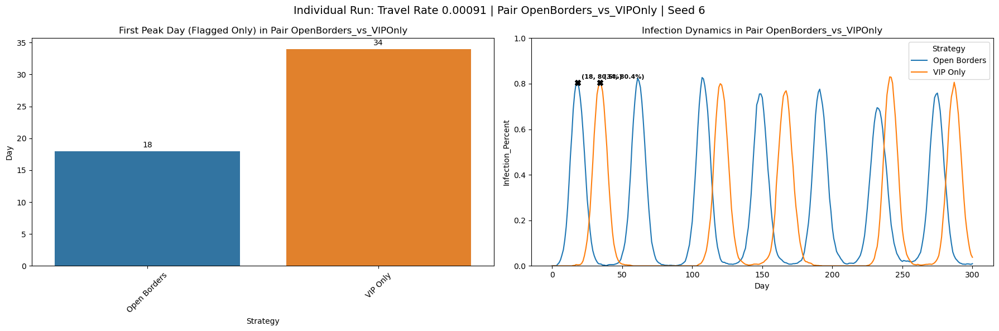

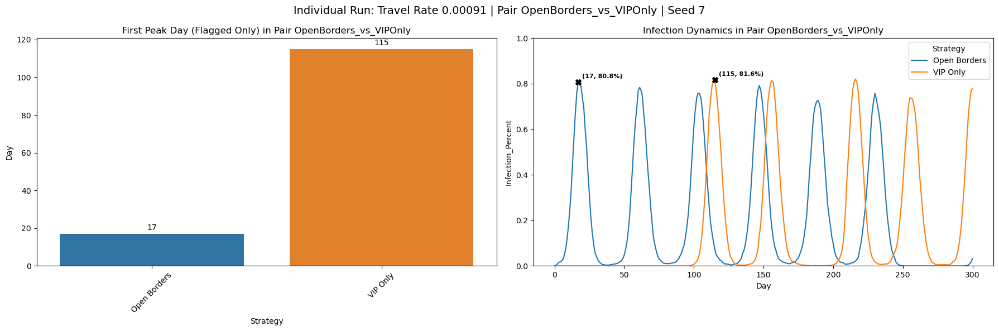

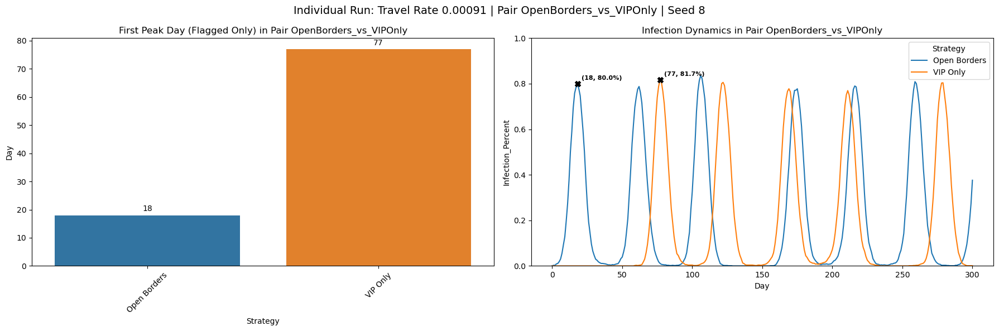

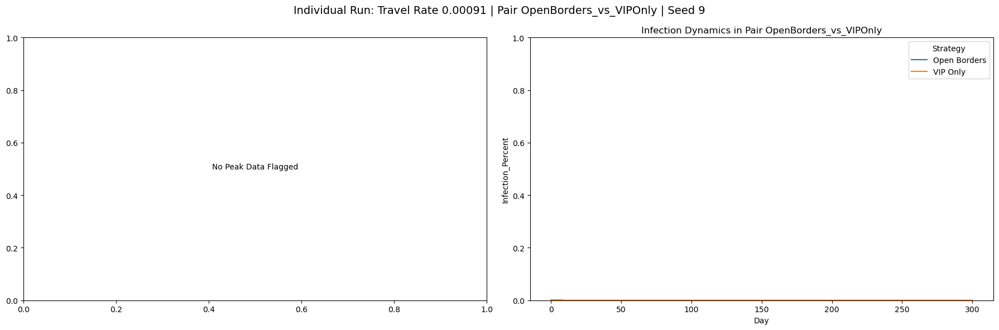

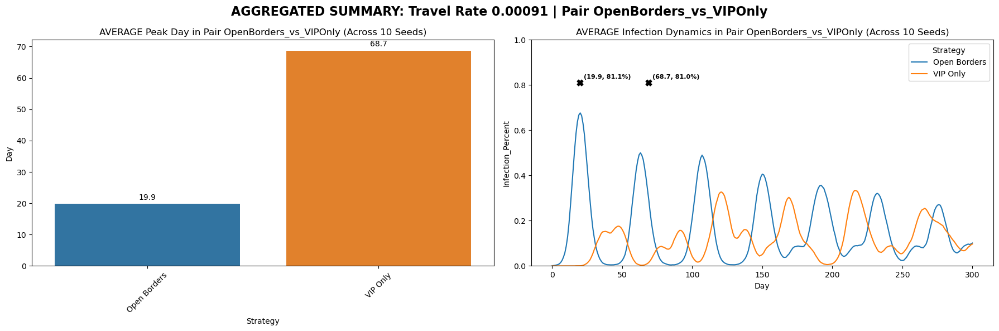


=== Processing: Rate 0.00274 | Pair OpenBorders_vs_LongQuarantine ===


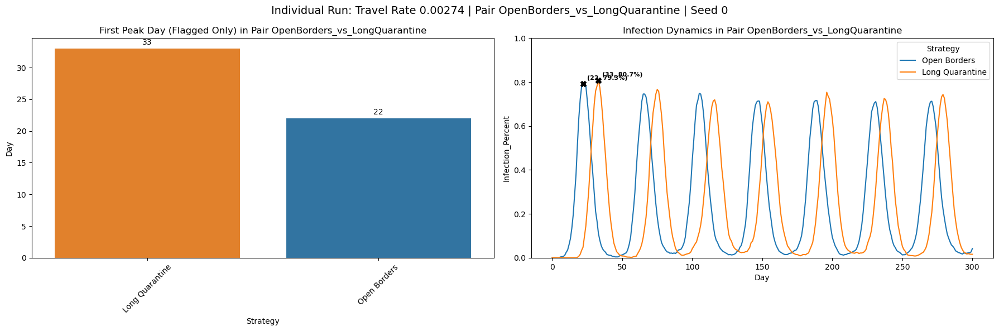

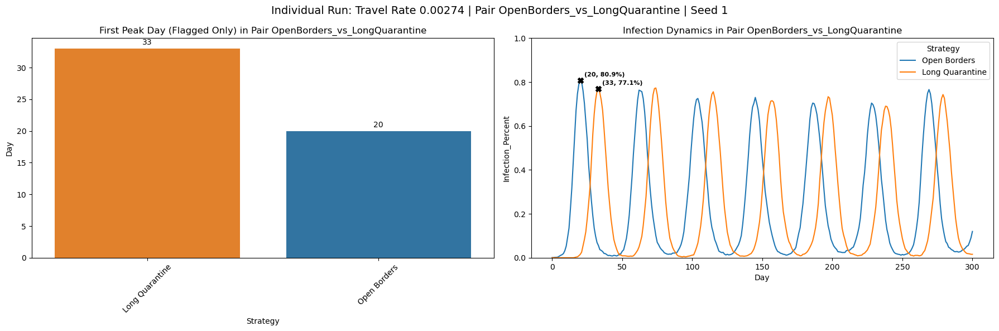

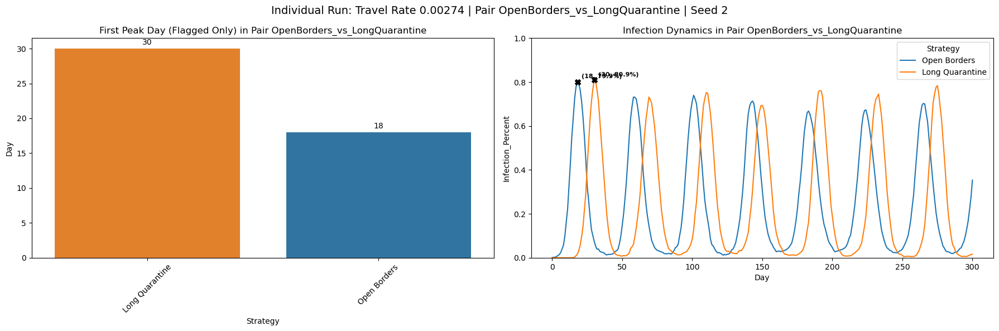

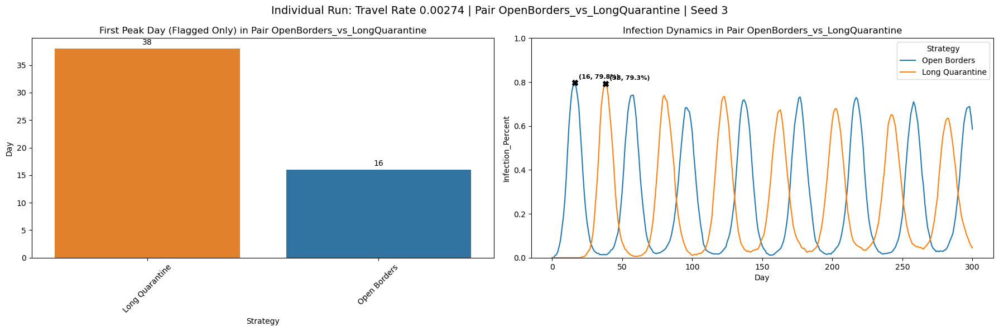

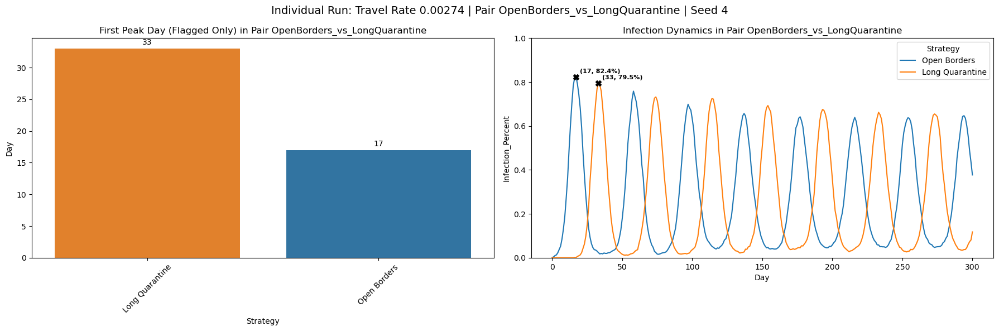

...

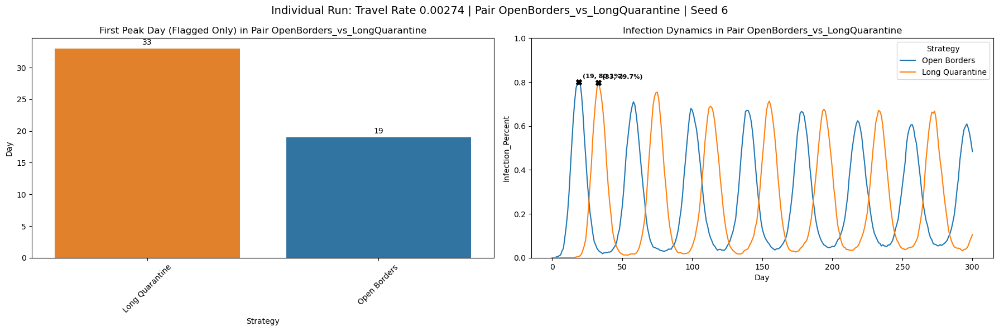

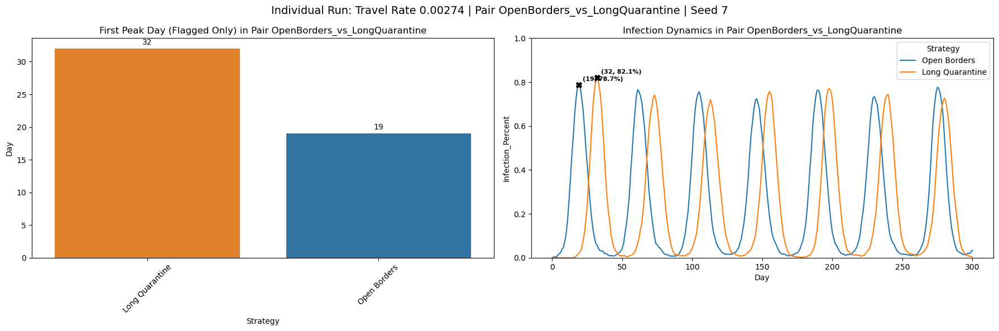

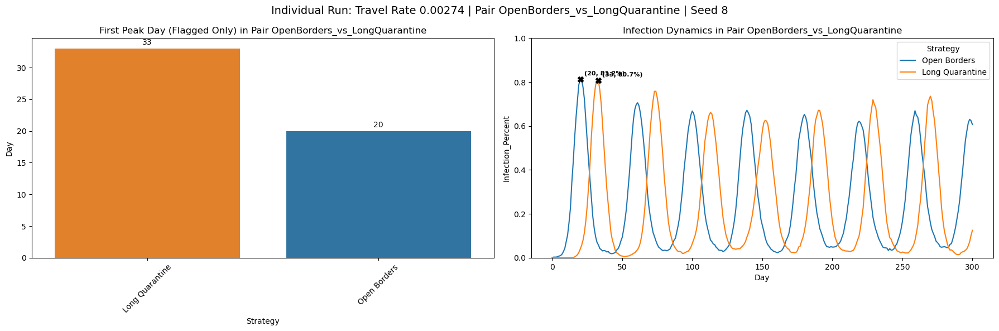

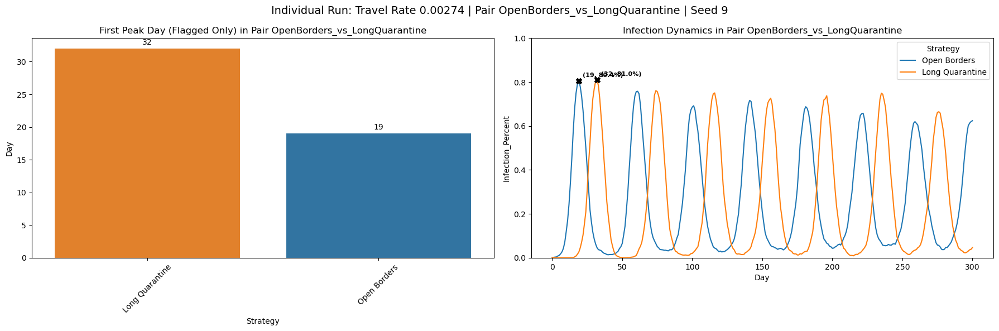

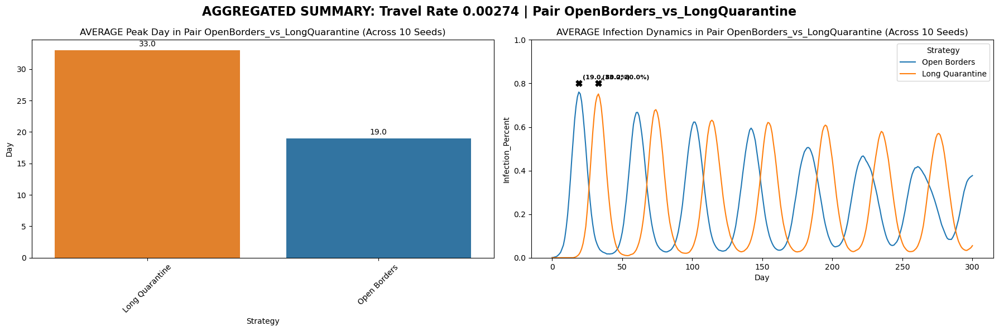


=== Processing: Rate 0.00274 | Pair OpenBorders_vs_NegativeTest ===


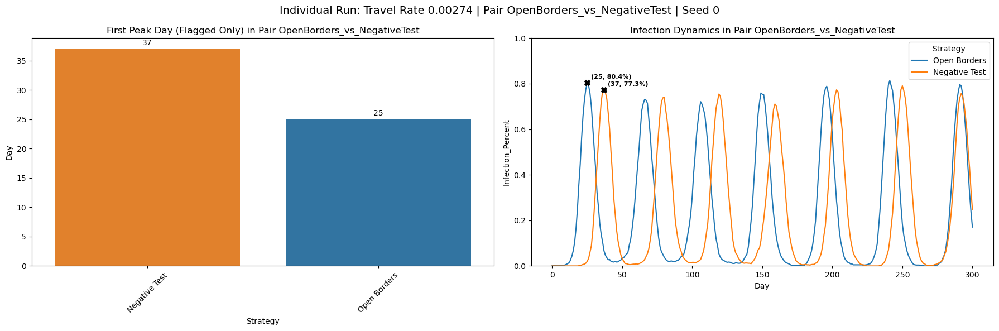

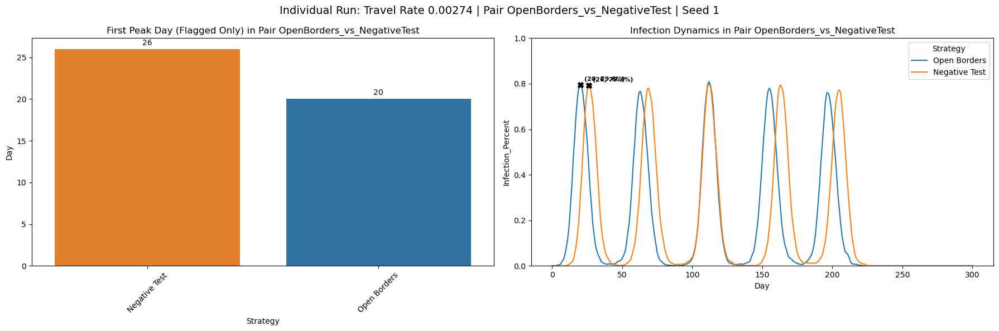

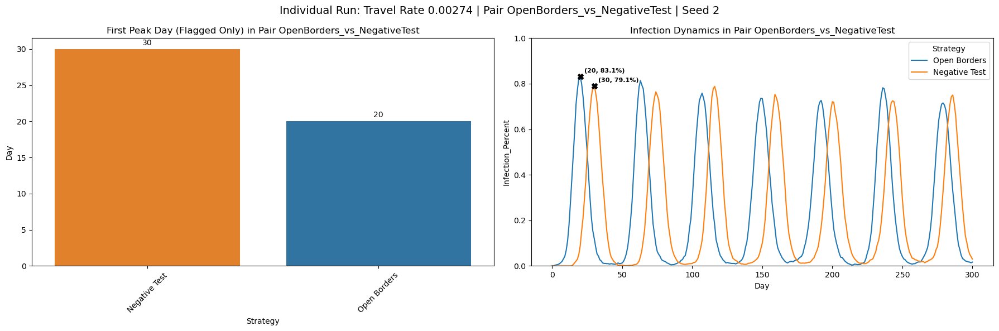

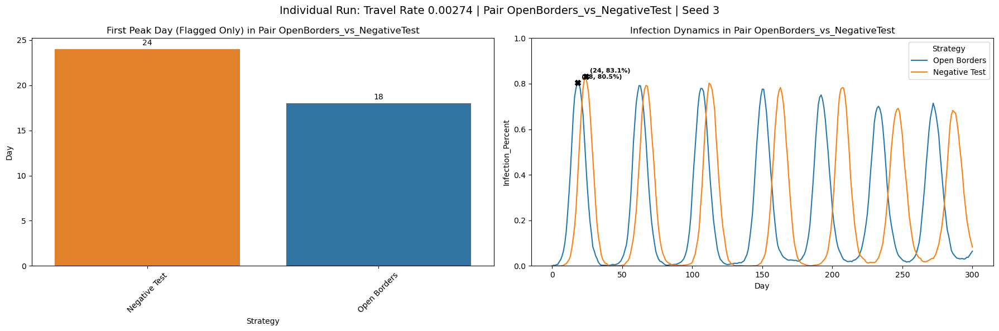

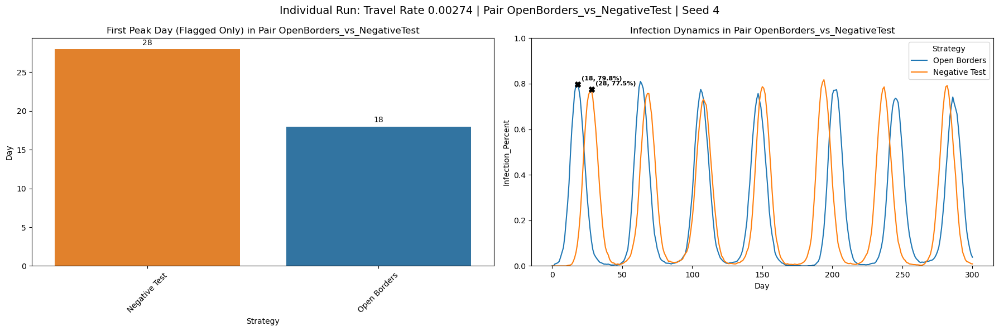

...

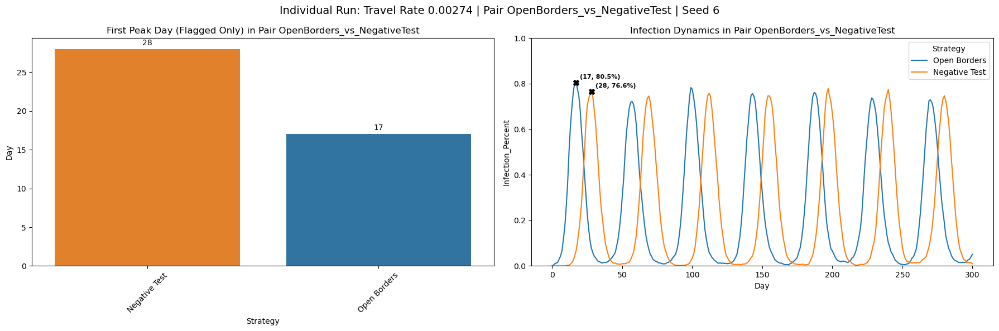

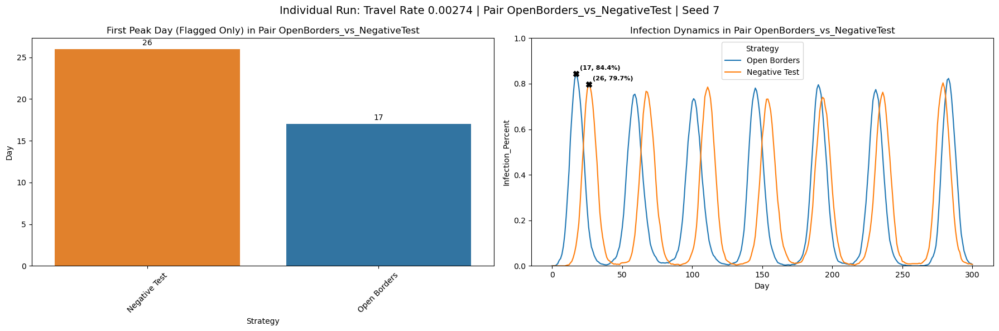

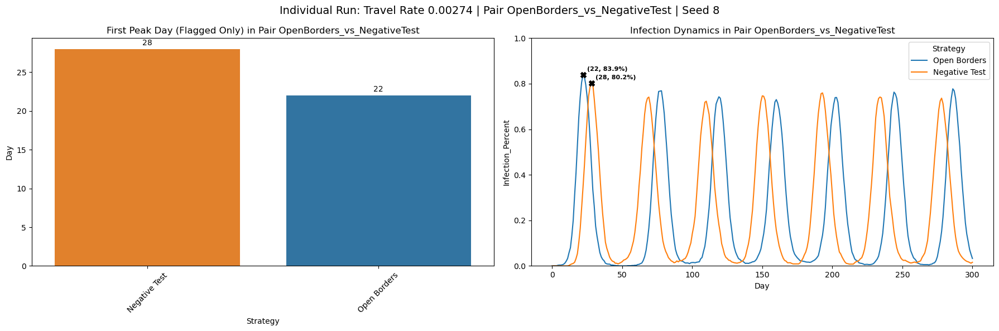

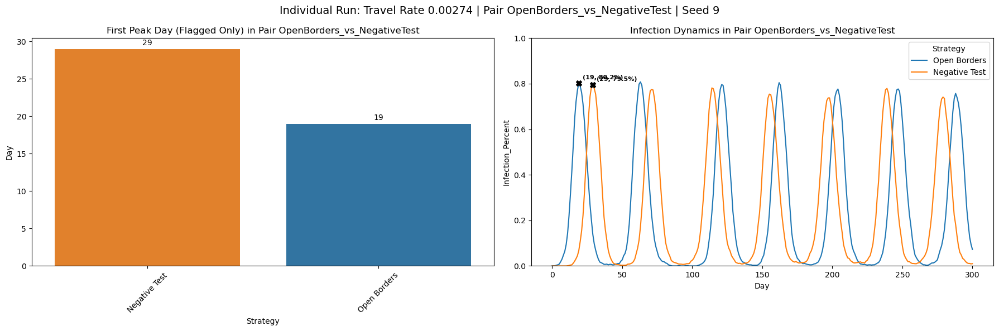

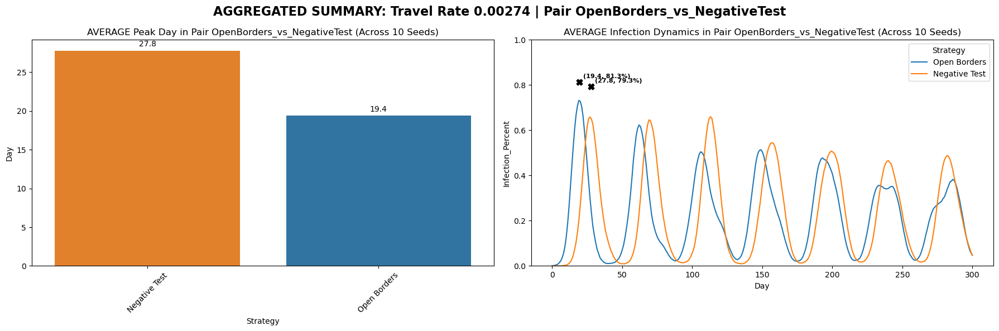


=== Processing: Rate 0.00274 | Pair OpenBorders_vs_ShortQuarantine ===


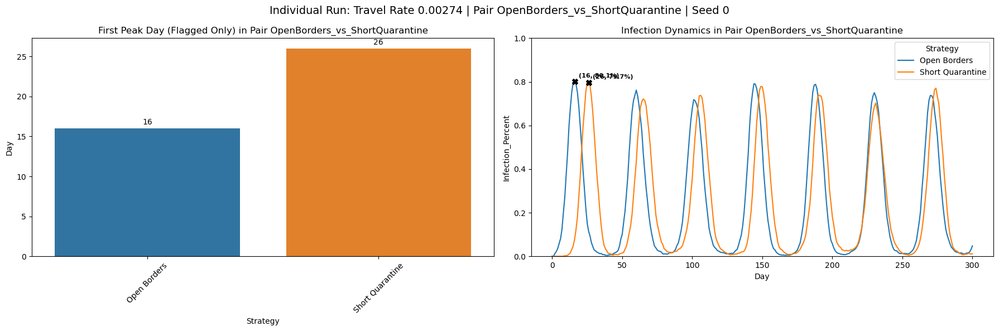

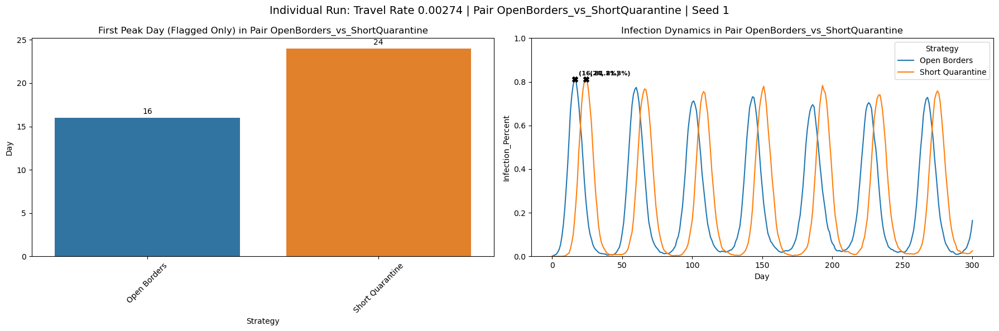

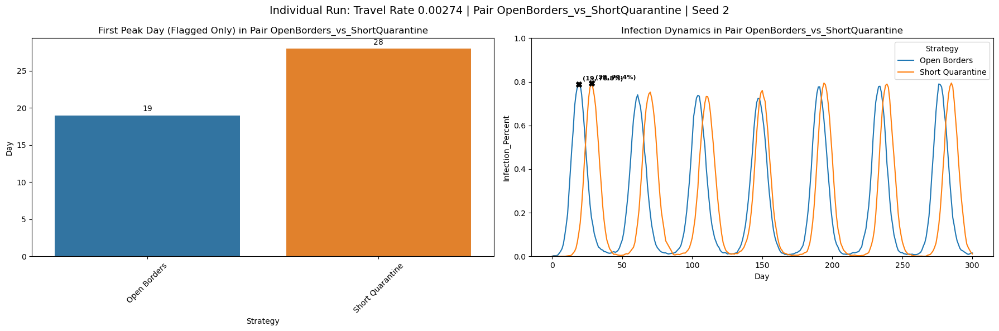

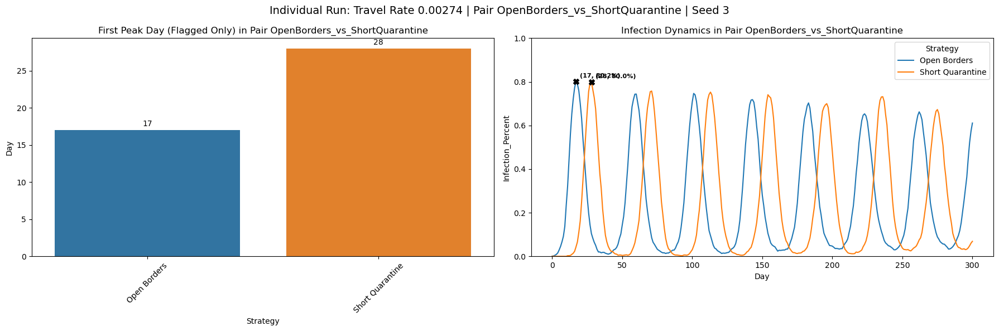

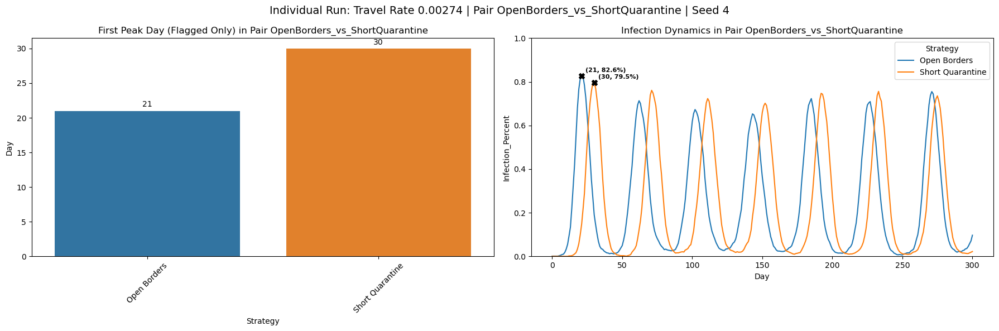

...

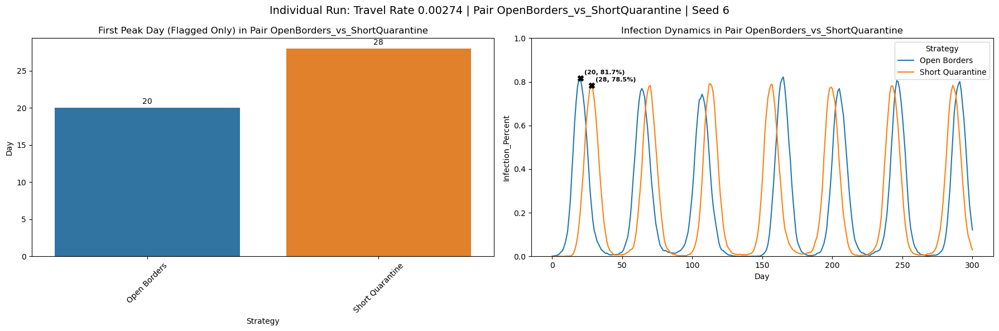

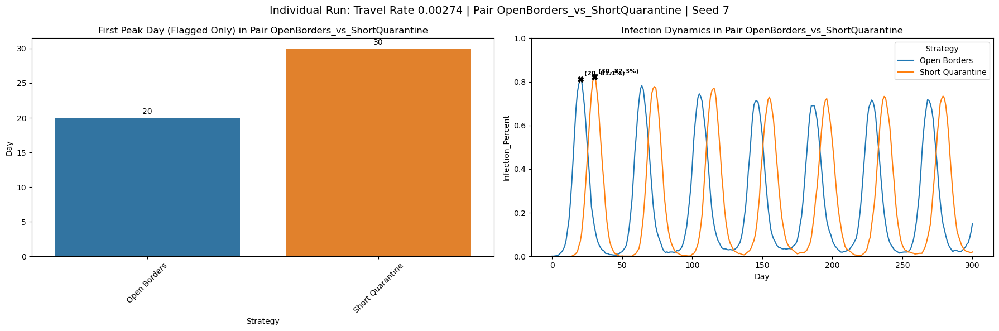

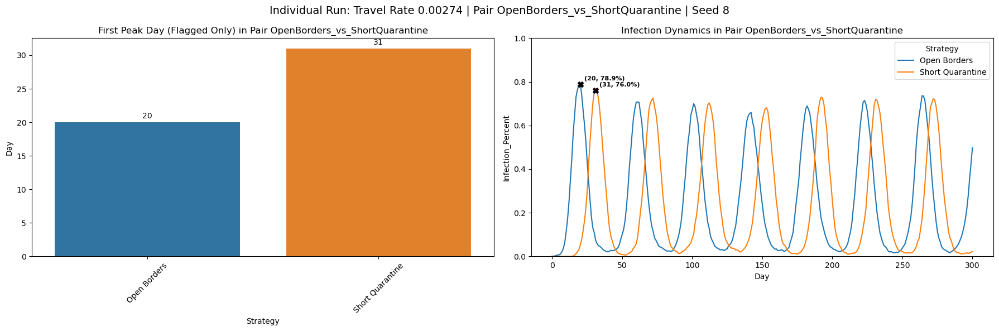

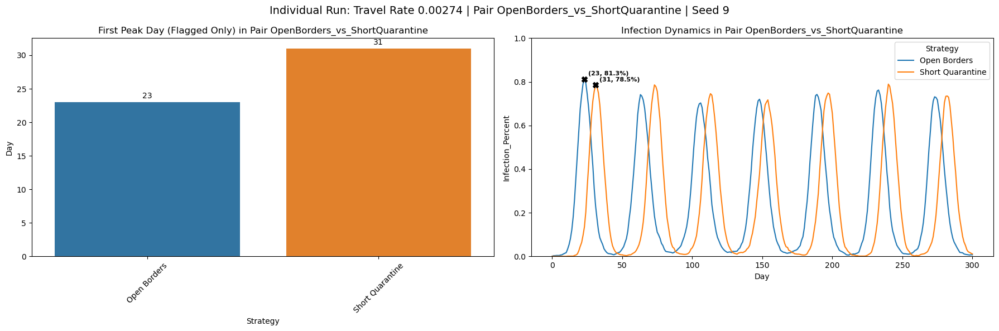

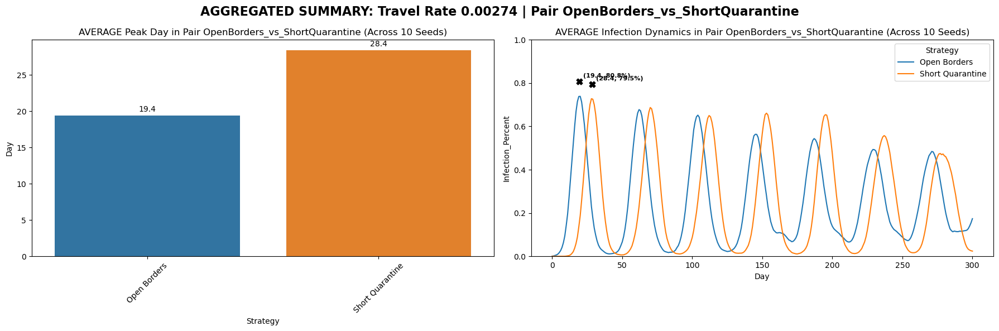


=== Processing: Rate 0.00274 | Pair OpenBorders_vs_VIPOnly ===


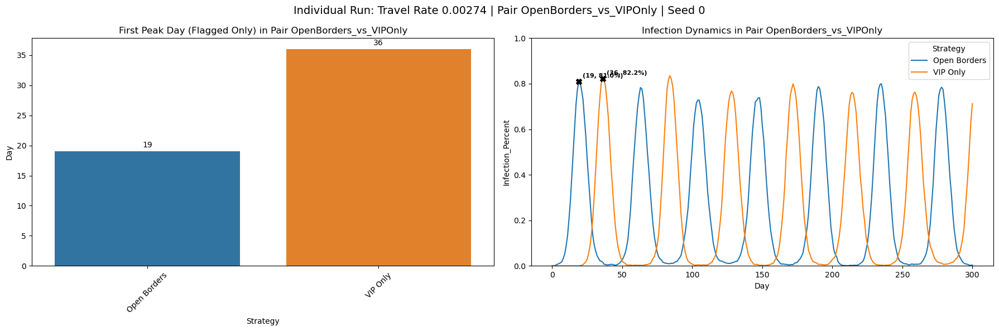

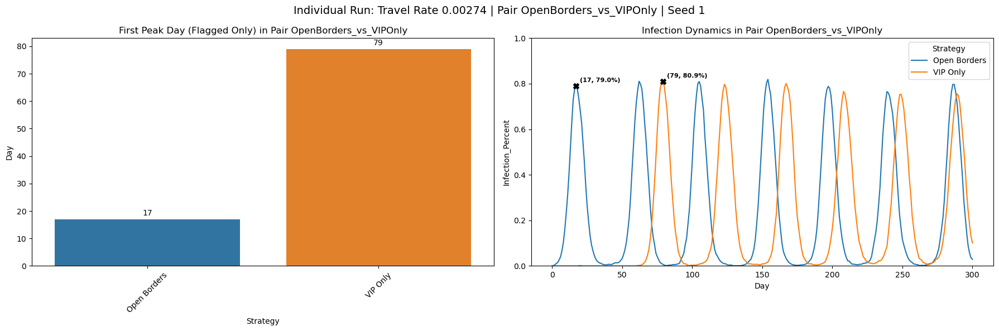

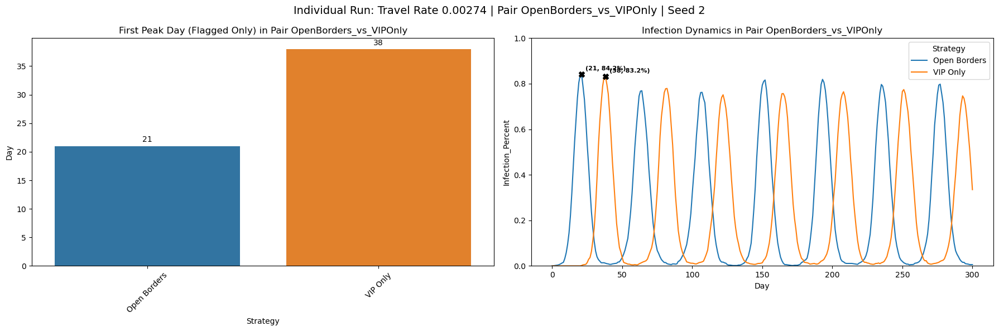

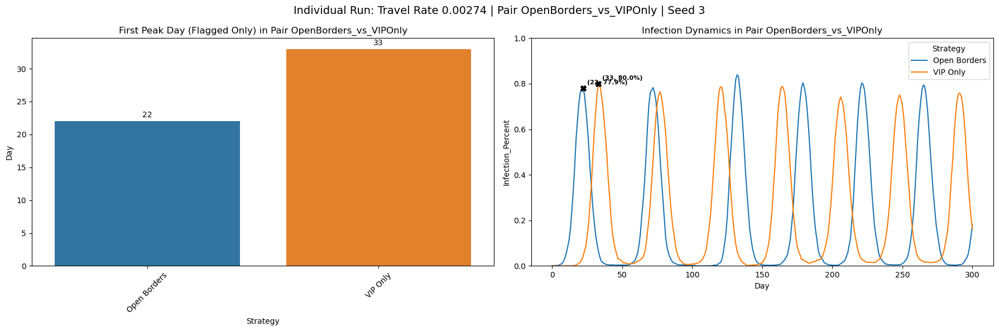

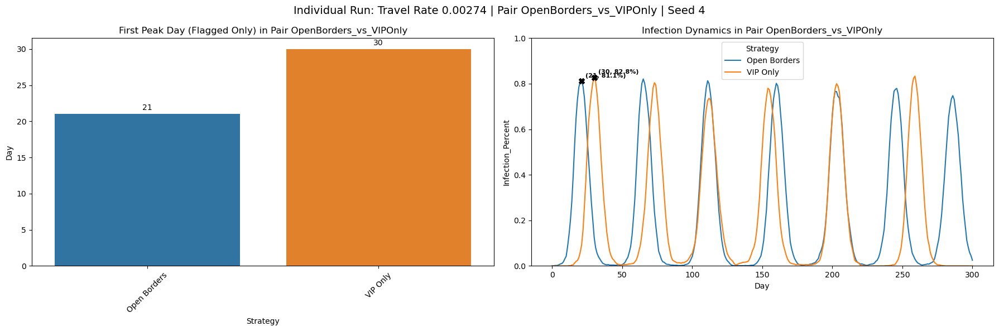

...

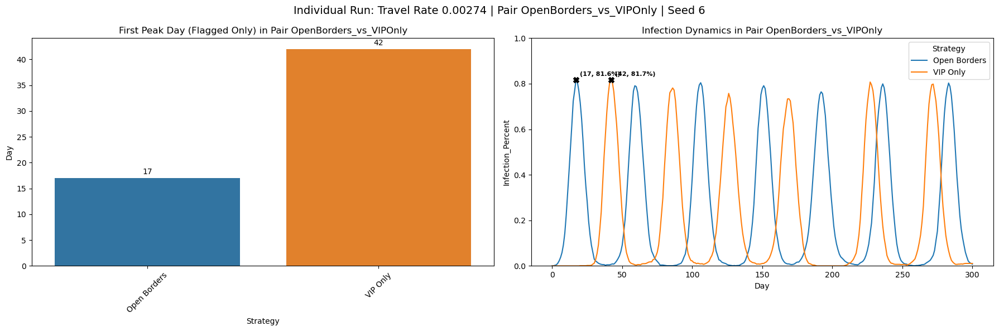

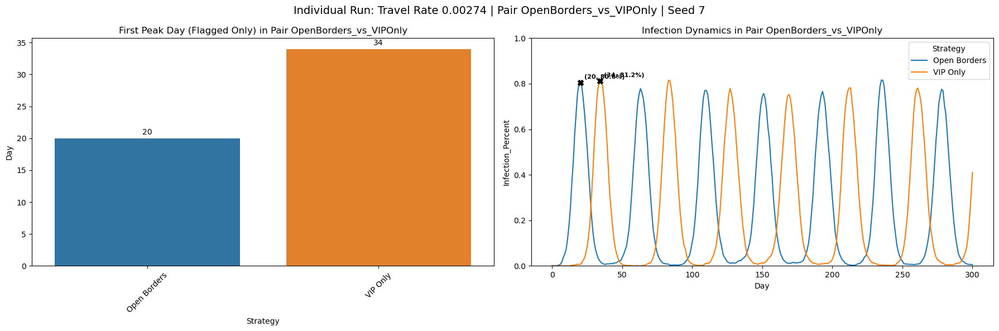

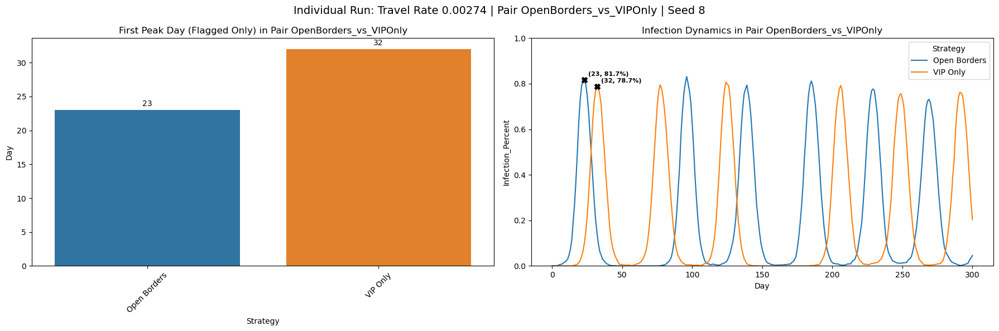

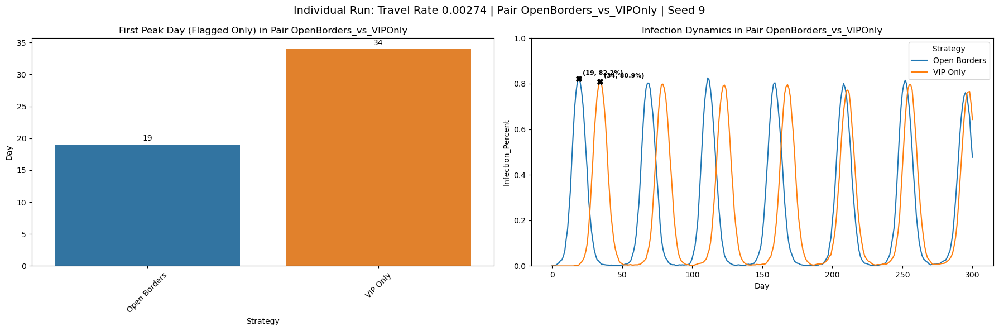

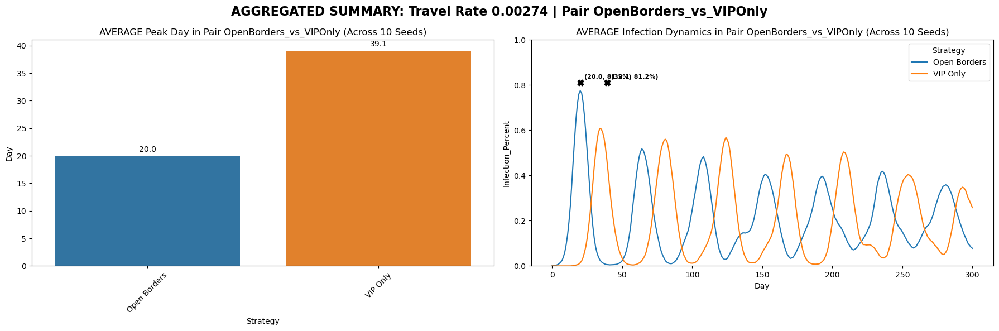


=== Processing: Rate 0.00822 | Pair OpenBorders_vs_LongQuarantine ===


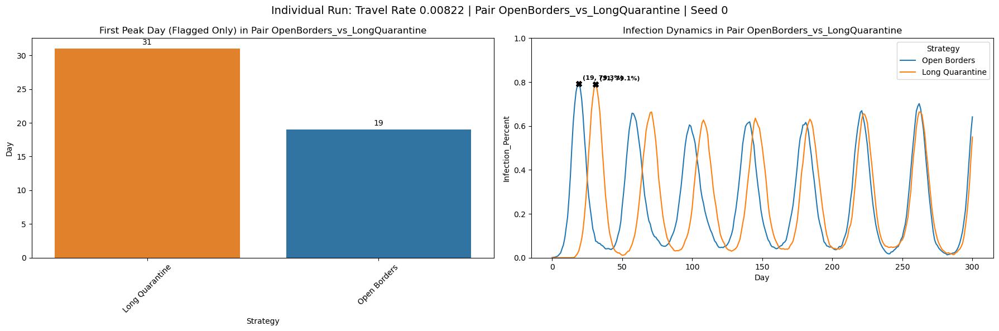

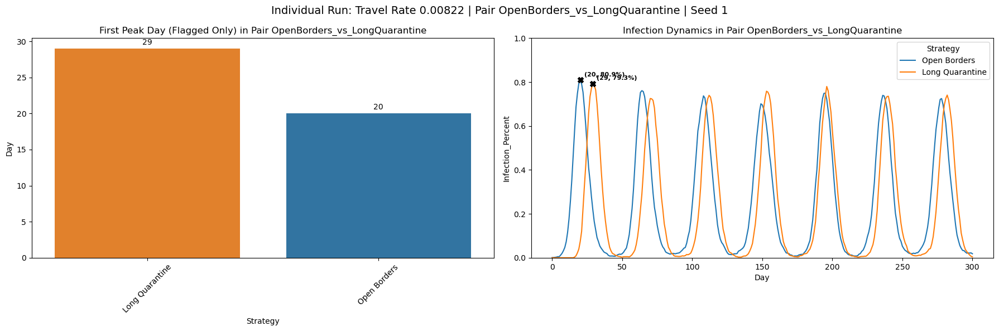

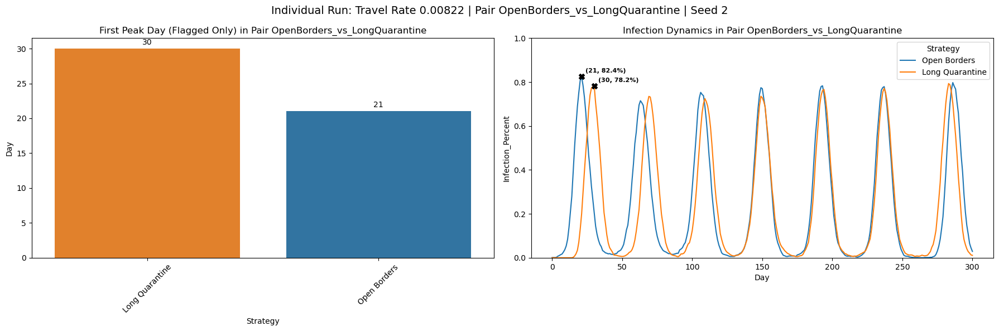

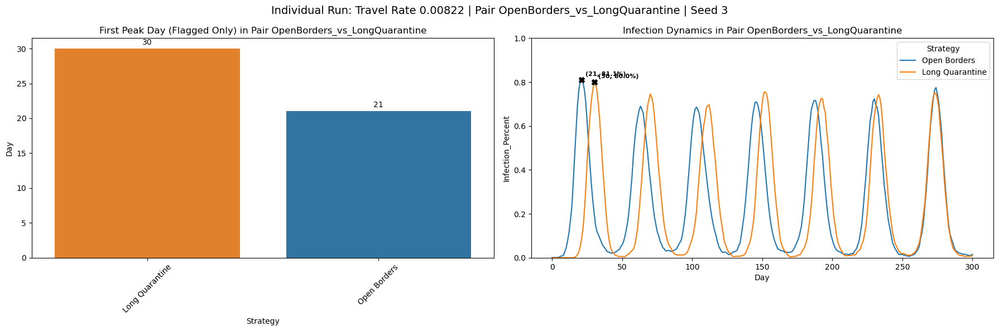

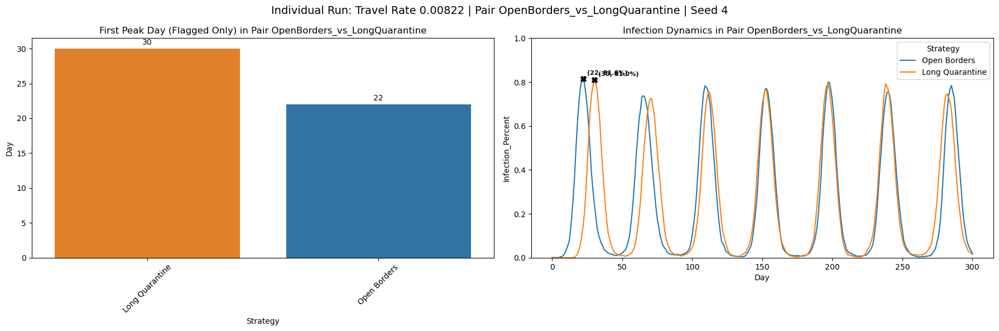

...

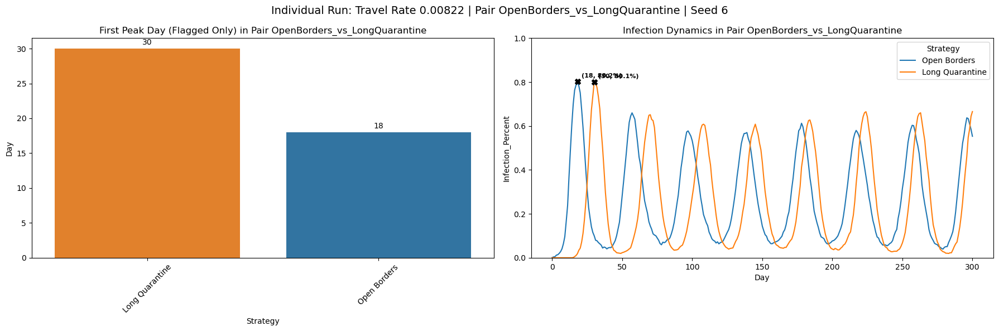

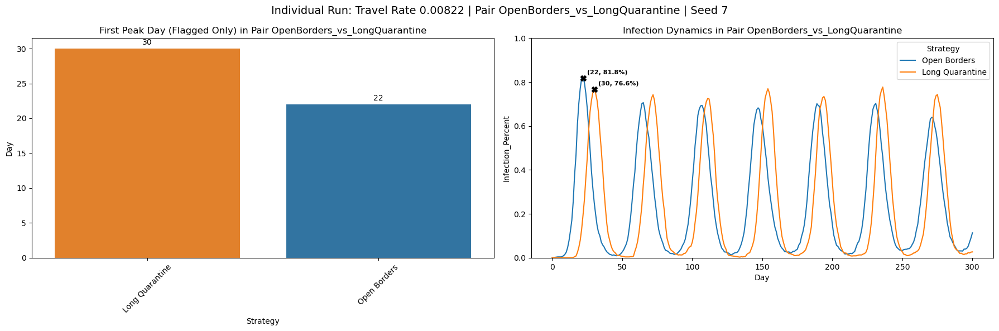

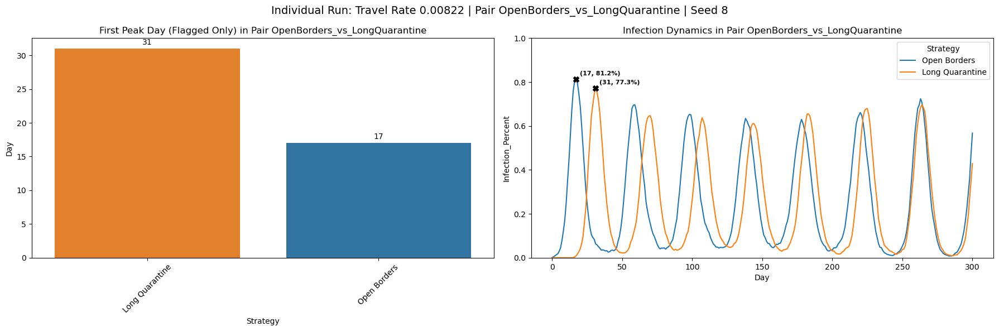

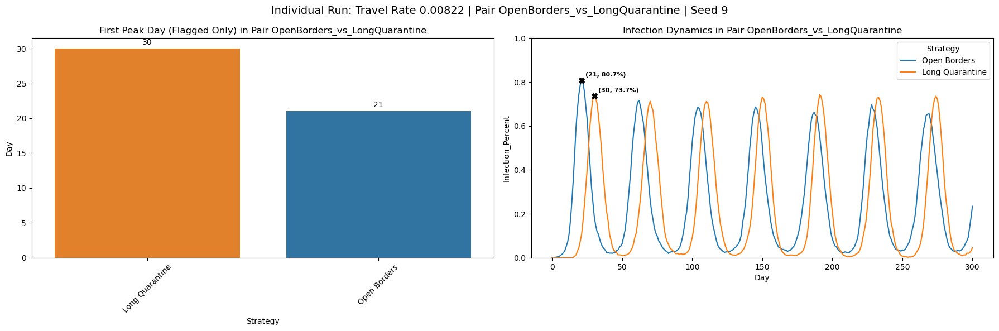

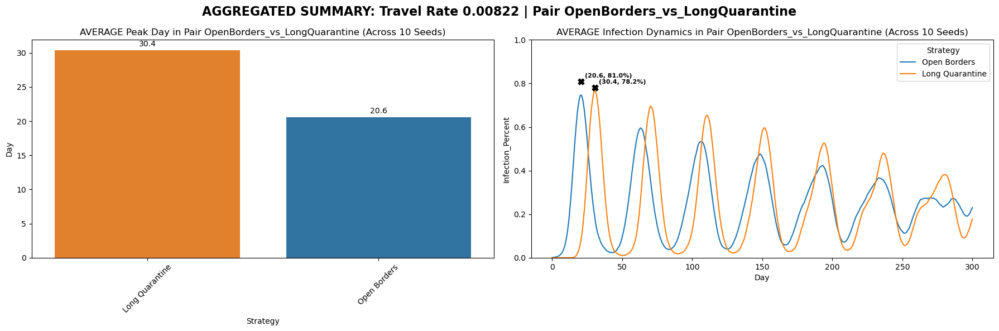


=== Processing: Rate 0.00822 | Pair OpenBorders_vs_NegativeTest ===


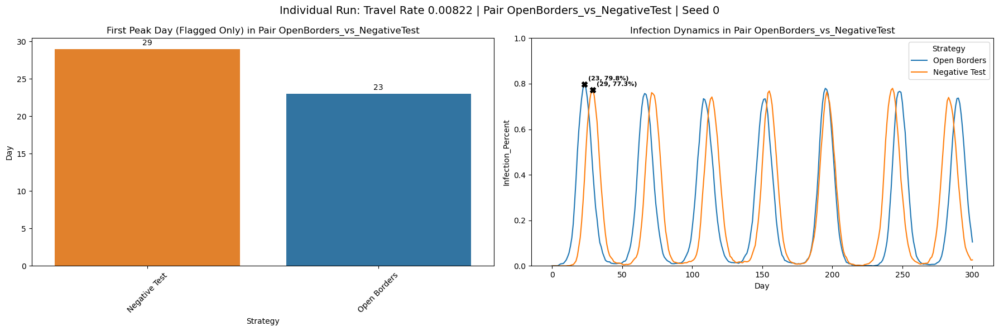

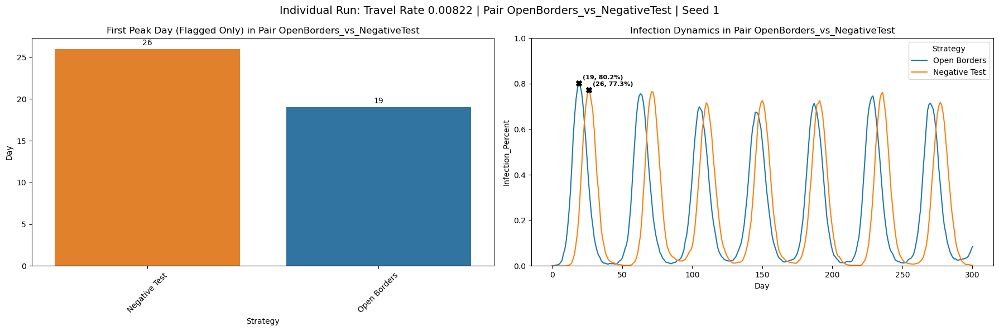

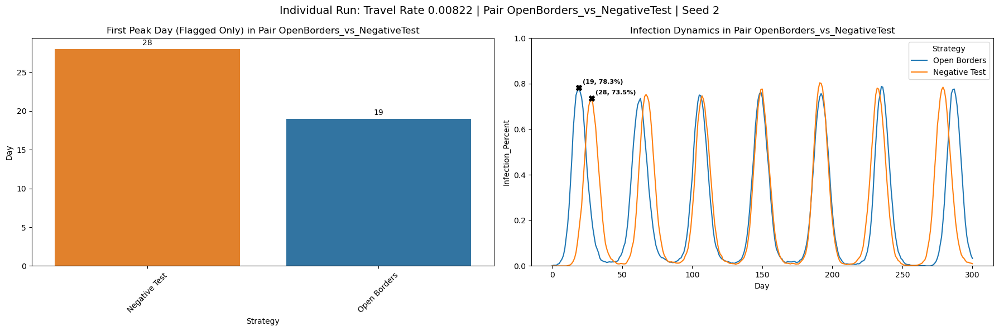

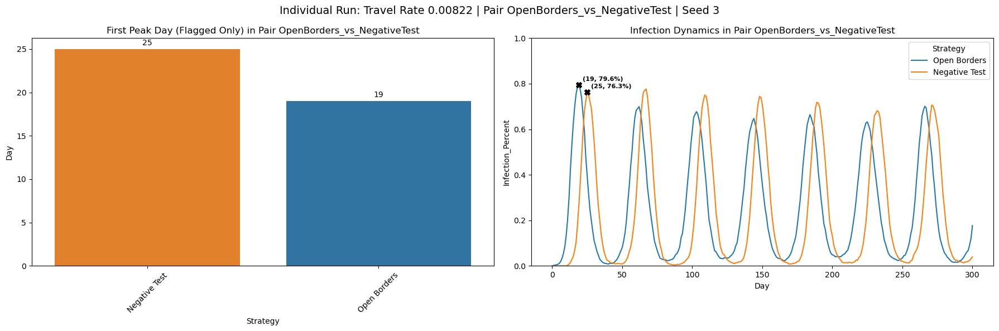

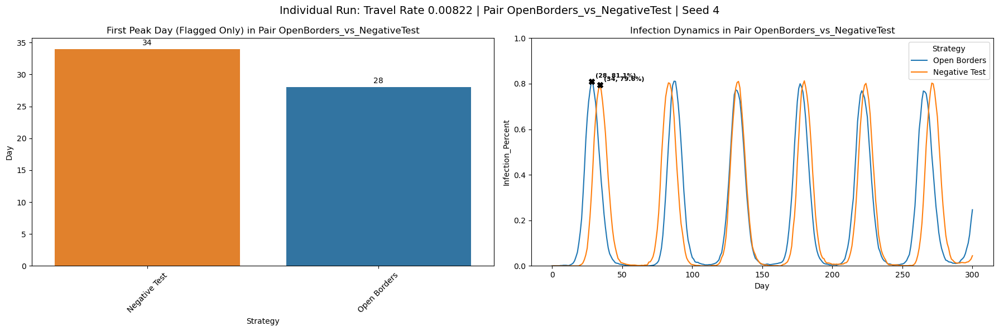

...

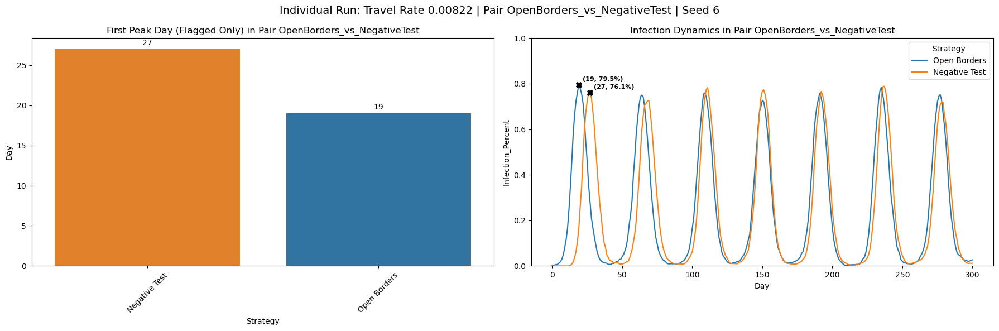

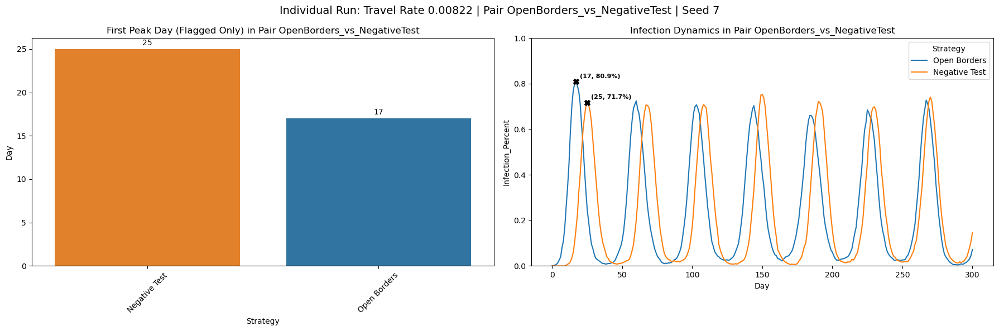

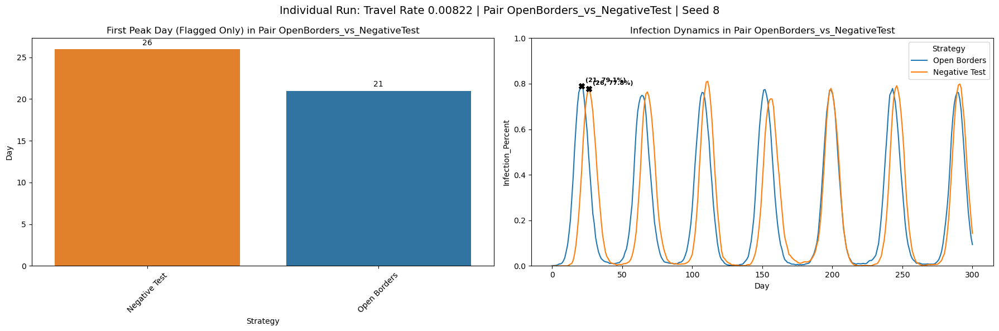

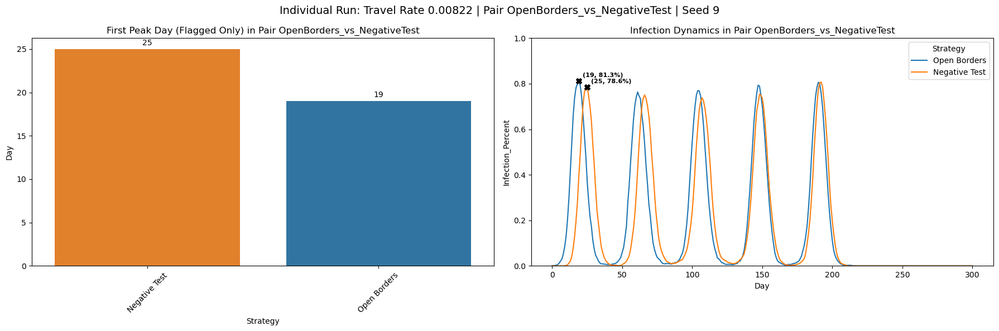

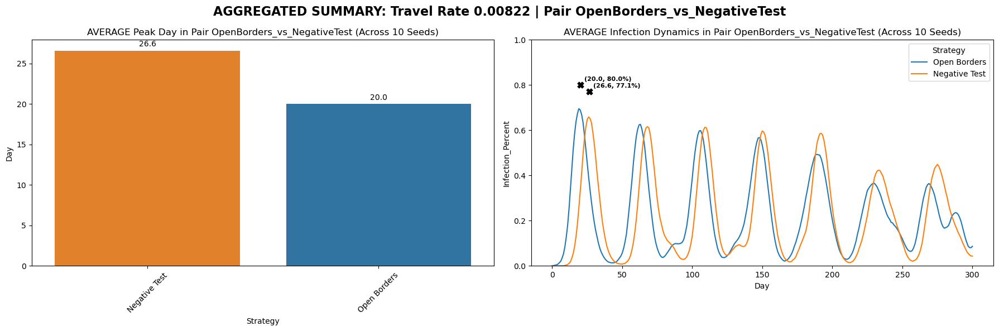


=== Processing: Rate 0.00822 | Pair OpenBorders_vs_ShortQuarantine ===


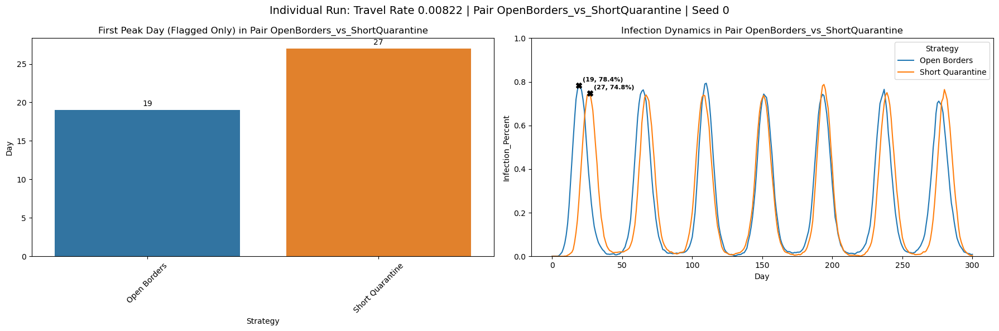

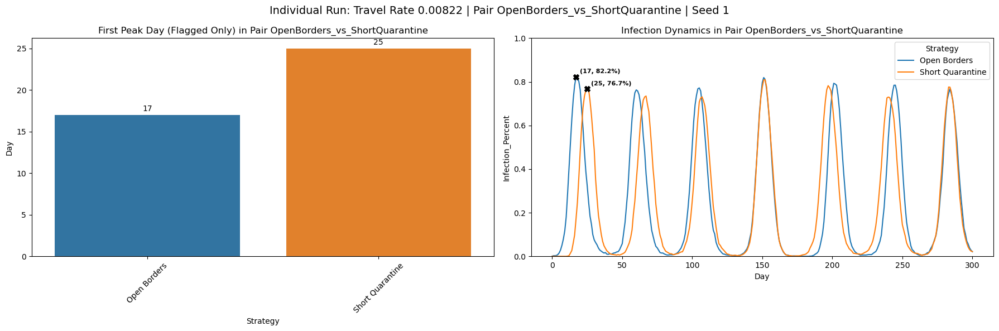

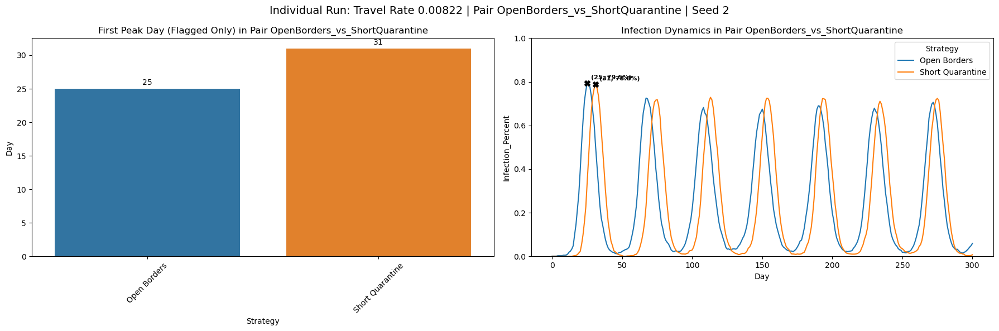

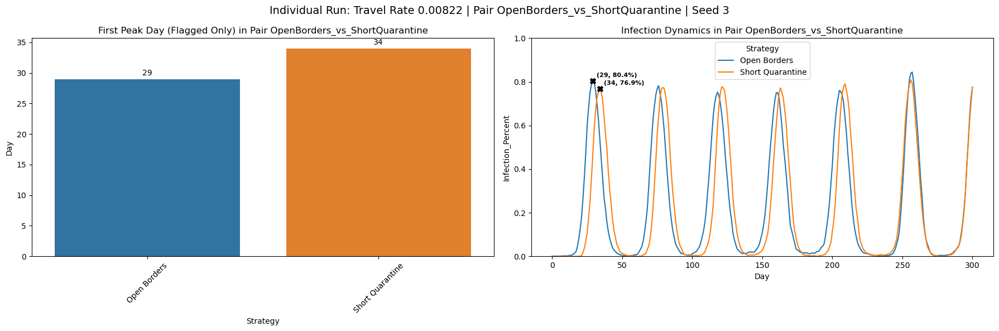

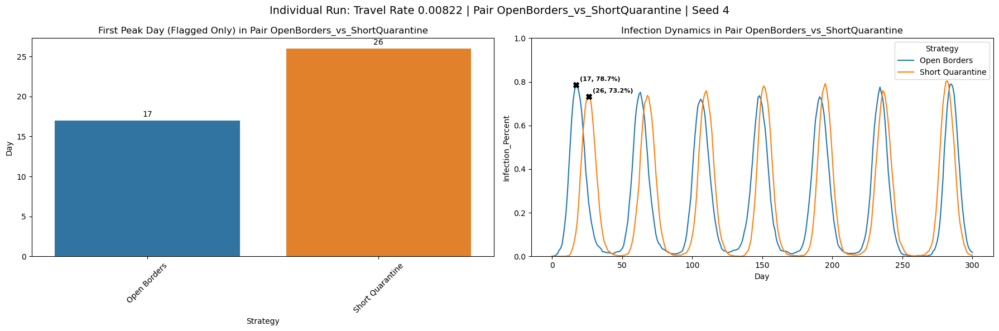

...

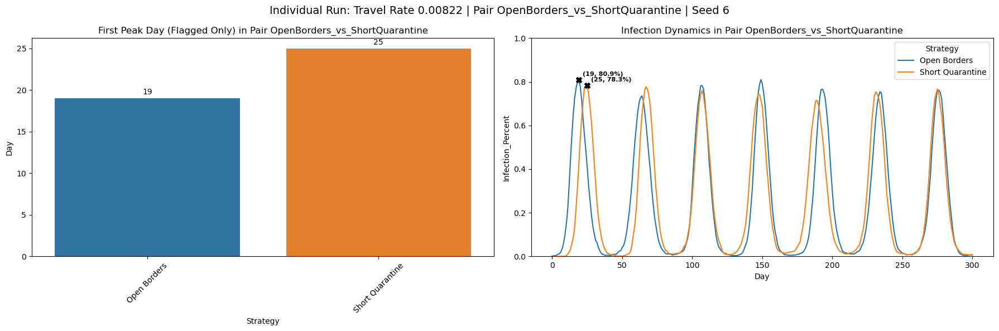

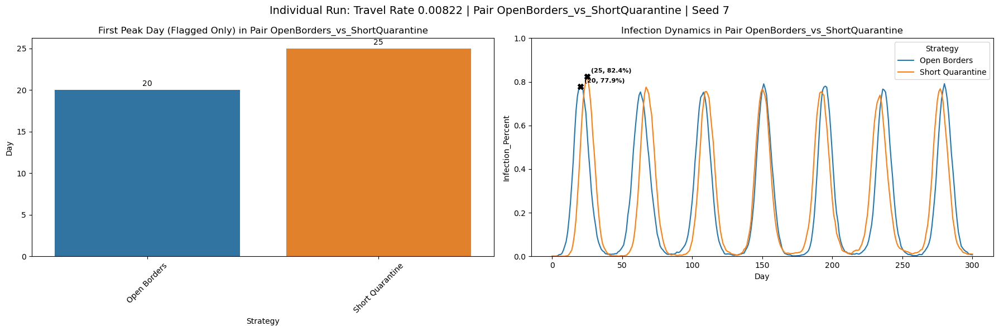

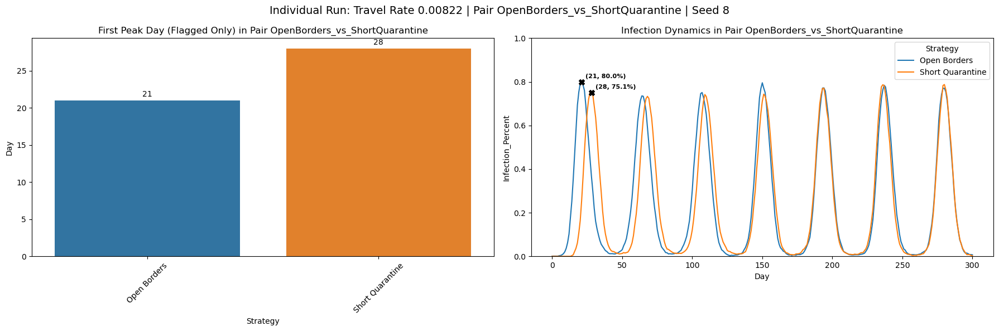

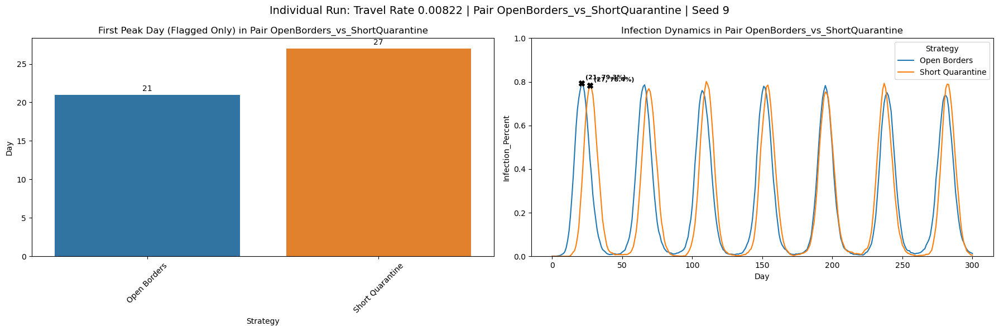

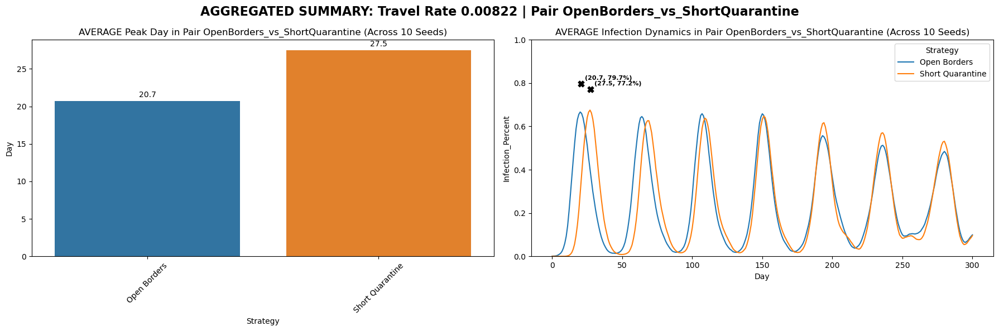


=== Processing: Rate 0.00822 | Pair OpenBorders_vs_VIPOnly ===


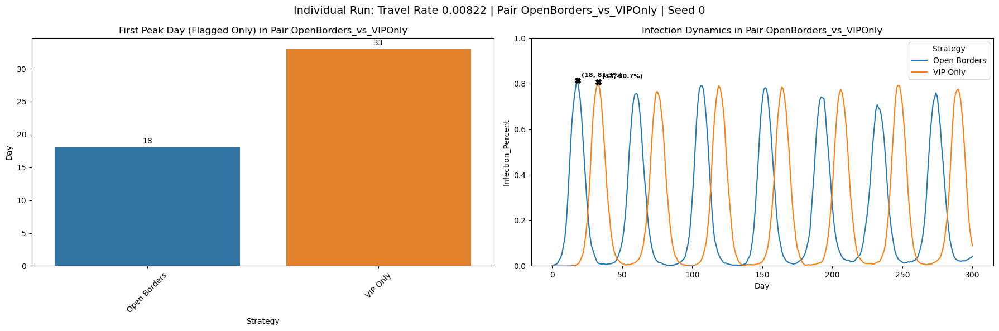

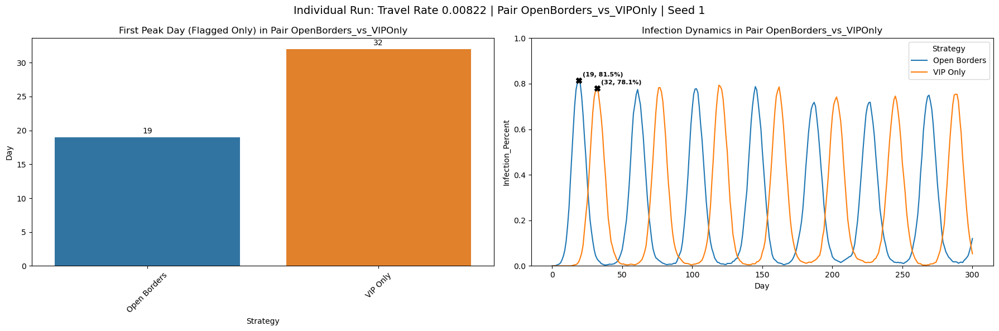

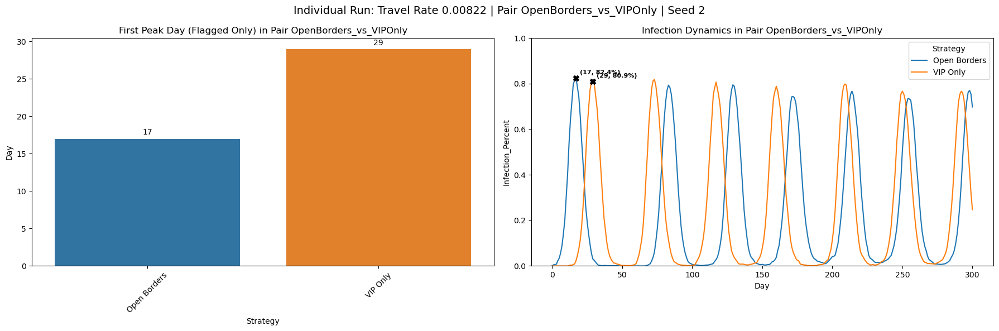

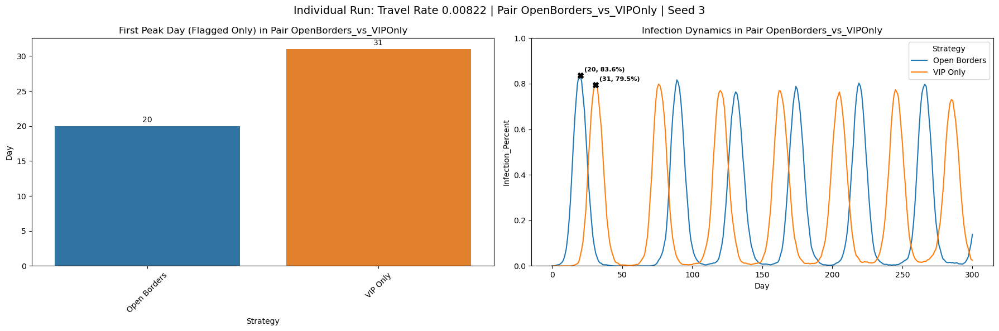

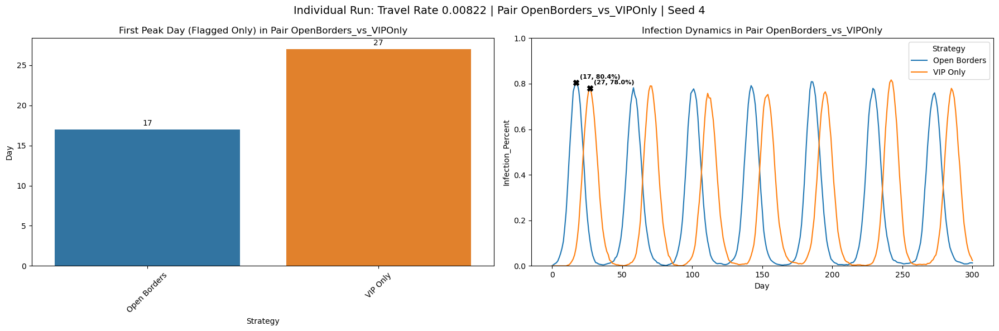

...

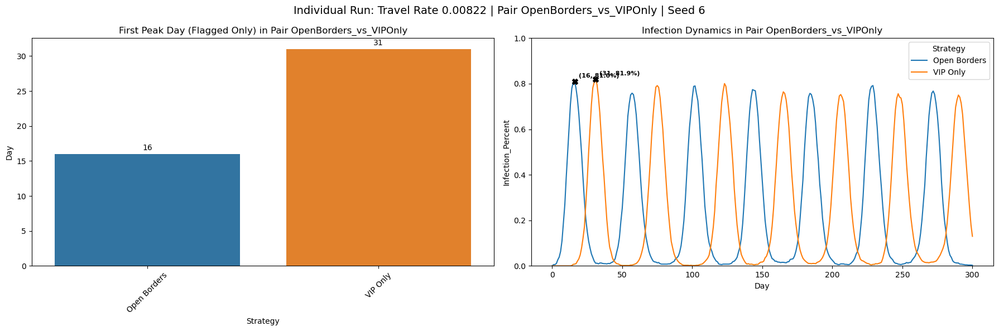

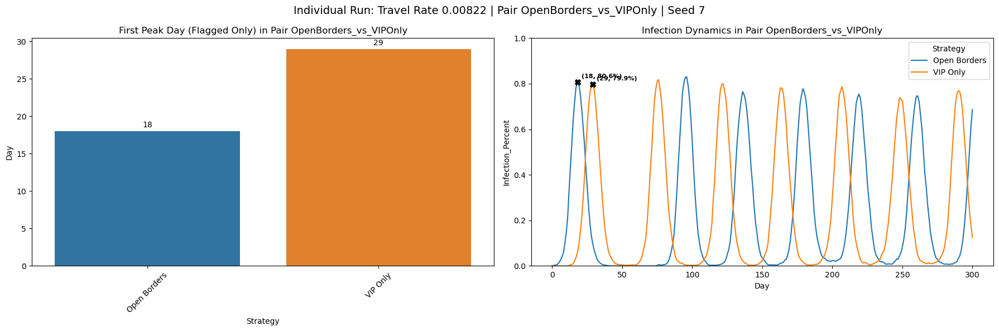

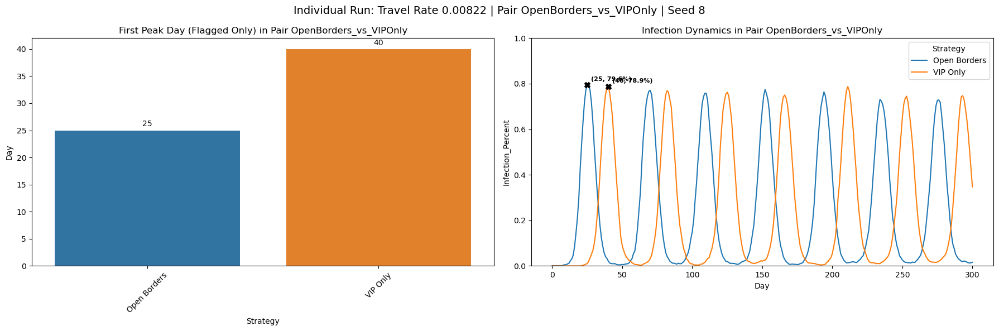

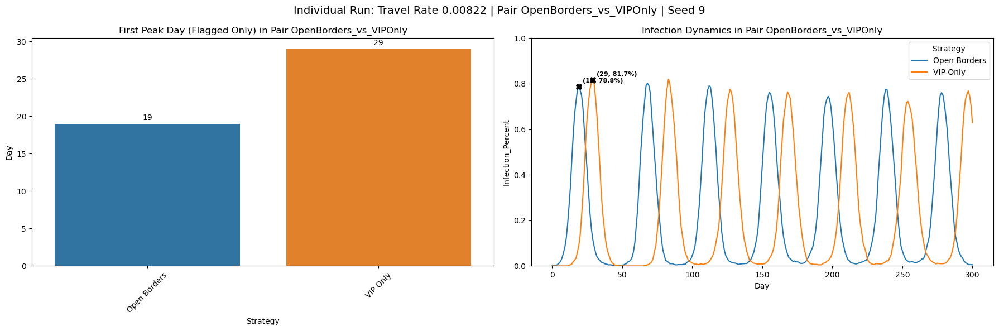

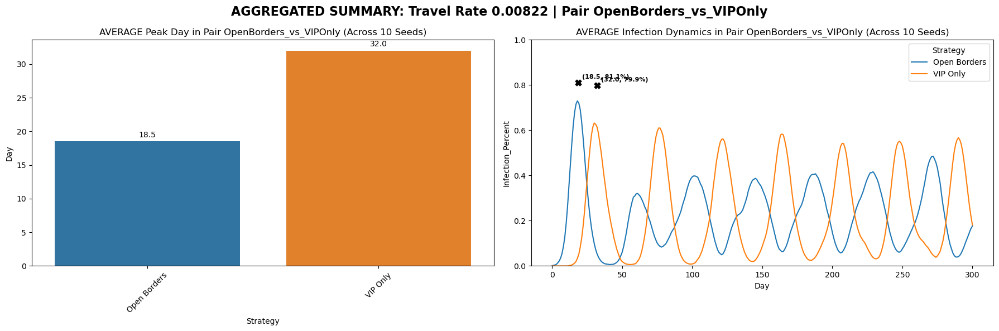

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------------------------------------
# 1. DATA LOADING AND PRE-PROCESSING
# ---------------------------------------------------------

# Load the new pairwise csv file
filename = "pairwise_batch_with_peaks.csv"
modelDat = pd.read_csv(filename)

# Rename columns as requested
# Mapping 'iteration' to 'Seed'. 'RunId' and 'seed_country' are ignored as per user request.
modelDat = modelDat.rename(columns={"Step": "Day", "iteration": "Seed"})

# Identify ALL potential Strategy names based on columns ending with '_InfectionPercent'
# We explicitly filter out the aggregated 'InfectionPercent' column.
strategy_cols = [c for c in modelDat.columns if c.endswith('_InfectionPercent')]
strategies = [s.replace("_InfectionPercent", "") for s in strategy_cols]

# Create a mapping from the space-less name (used in PairConfig) to the space-ful name (used in columns)
strategy_name_map = {s.replace(" ", ""): s for s in strategies}

print(f"All potential strategies detected: {strategies}")
print(f"Strategy mapping created: {strategy_name_map}")


# ---------------------------------------------------------
# 2. EXTRACT PEAK DATA (Only Explicitly Flagged Peaks)
# ---------------------------------------------------------

peak_records = []

# Get unique identifiers to iterate through, ignoring 'seed_country'
unique_seeds = modelDat['Seed'].unique()
unique_rates = modelDat['param_travel_rate'].unique()
unique_pairs = modelDat['PairConfig'].unique()

# We iterate through all unique run combinations (rate, pair, seed)
for rate in unique_rates:
    for pair_config in unique_pairs:
        for seed in unique_seeds:
            
            # Subset for this specific run. Note: 'seed_country' is fixed to 0.
            # We use 'pair_id' and 'PairConfig' interchangeably here, with PairConfig being more descriptive.
            run_data = modelDat[
                (modelDat['param_travel_rate'] == rate) & 
                (modelDat['PairConfig'] == pair_config) &
                (modelDat['Seed'] == seed)
            ]
            
            if run_data.empty:
                continue
            
            # Determine the two active strategies in this pair (space-less names from PairConfig)
            space_less_strategies = pair_config.split('_vs_')

            for space_less_strategy in space_less_strategies:
                # Translate to the correct, space-ful strategy name for column access
                strategy = strategy_name_map.get(space_less_strategy)
                
                if not strategy:
                    print(f"Warning: Could not find strategy '{space_less_strategy}' in map. Skipping.")
                    continue
                    
                peak_col = f"{strategy}_IsFirstPeak"
                inf_col = f"{strategy}_InfectionPercent"
                
                # Only process rows where the peak is explicitly flagged
                peak_rows = run_data[run_data[peak_col] == 1]
                
                if not peak_rows.empty:
                    # Take the first one (should be only one per run for that strategy)
                    row = peak_rows.iloc[0]
                    peak_records.append({
                        'Seed': row['Seed'],
                        'Day': row['Day'],
                        # Removed 'seed_country' as it's constant
                        'param_travel_rate': row['param_travel_rate'],
                        'PairConfig': row['PairConfig'],
                        'Strategy': strategy,
                        'Peak_Infection_Rate': row[inf_col],
                    })

# Create the summary dataframe
peaks_summary = pd.DataFrame(peak_records)

# Sort for consistency
peaks_summary = peaks_summary.sort_values(
    by=['param_travel_rate', 'PairConfig', 'Seed', 'Strategy', 'Day']
)
print(f"Peak summary extracted. Total peaks found: {len(peaks_summary)}")

# Helper function to add labels to bar charts
def add_bar_labels(ax, fmt='%.1f'):
    for container in ax.containers:
        # Check if container is a BarContainer before calling bar_label
        if hasattr(container, 'datavalues'):
            ax.bar_label(container, fmt=fmt, padding=3)

# ---------------------------------------------------------
# 3. MAIN LOOP: TRAVEL RATE -> PAIR CONFIG
# ---------------------------------------------------------

sorted_rates = sorted(unique_rates)
sorted_pairs = sorted(unique_pairs)

print(f"Found {len(sorted_rates)} Travel Rates and {len(sorted_pairs)} Pair Configurations.")

for rate in sorted_rates:
    for pair_config in sorted_pairs:

        # Filter Data for this specific combination
        subset_lines = modelDat[
            (modelDat['param_travel_rate'] == rate) & 
            (modelDat['PairConfig'] == pair_config)
        ].copy()
        
        subset_peaks = peaks_summary[
            (peaks_summary['param_travel_rate'] == rate) & 
            (peaks_summary['PairConfig'] == pair_config)
        ].copy()
        
        if subset_lines.empty:
            continue

        # Get the correct, space-ful strategy names for this pair
        space_less_strats = pair_config.split('_vs_')
        active_strats = [strategy_name_map[s] for s in space_less_strats if s in strategy_name_map]
        
        if not active_strats:
            continue

        print(f"\n=== Processing: Rate {rate:.5f} | Pair {pair_config} ===")
        
        # Melt line data for Seaborn, only including the two active strategies' columns
        # This explicitly ignores the aggregated 'InfectionPercent' column
        active_cols = [f"{s}_InfectionPercent" for s in active_strats]
        
        melted_lines = subset_lines.melt(
            id_vars=['Day', 'Seed'], 
            value_vars=active_cols,
            var_name='Strategy_Col', 
            value_name='Infection_Percent'
        )
        # The 'Strategy' column already contains the space-ful names now
        melted_lines['Strategy'] = melted_lines['Strategy_Col'].str.replace("_InfectionPercent", "")

        # Prepare Colors
        unique_strats = melted_lines['Strategy'].unique()
        palette = sns.color_palette('tab10', n_colors=len(unique_strats))
        strat_colors = dict(zip(unique_strats, palette))
        
        current_seeds = subset_lines['Seed'].unique()
        
        # -----------------------------------------------------
        # GRAPHIC TYPE A: INDIVIDUAL SEED PLOTS 
        # -----------------------------------------------------
        for seed in current_seeds:
            fig, axes = plt.subplots(1, 2, figsize=(18, 6))
            
            # Data for this specific seed
            this_seed_peaks = subset_peaks[subset_peaks['Seed'] == seed]
            this_seed_lines = melted_lines[melted_lines['Seed'] == seed]
            
            # -- LEFT PLOT: BAR CHART (First Peak Day) --
            if not this_seed_peaks.empty:
                sns.barplot(
                    ax=axes[0],
                    data=this_seed_peaks,
                    x='Strategy',
                    y='Day',
                    hue='Strategy',
                    palette=strat_colors,
                    dodge=False,
                    legend=False,
                    errorbar=None
                )
                add_bar_labels(axes[0], fmt='%.0f')
                axes[0].set_title(f"First Peak Day (Flagged Only) in Pair {pair_config}")
                axes[0].tick_params(axis='x', rotation=45)
            else:
                axes[0].text(0.5, 0.5, "No Peak Data Flagged", ha='center', transform=axes[0].transAxes)
            
            # -- RIGHT PLOT: LINE CHART (Dynamics) --
            if not this_seed_lines.empty:
                sns.lineplot(
                    ax=axes[1],
                    data=this_seed_lines,
                    x='Day',
                    y='Infection_Percent',
                    hue='Strategy',
                    palette=strat_colors,
                    errorbar=None
                )
                
                # Add Markers
                for _, row in this_seed_peaks.iterrows():
                    day_val = row['Day']
                    inf_val = row['Peak_Infection_Rate']
                    
                    axes[1].scatter(day_val, inf_val, color='black', marker='X', s=50, zorder=5)
                    axes[1].annotate(
                        f"({int(day_val)}, {inf_val:.1%})", 
                        xy=(day_val, inf_val), 
                        xytext=(5, 5), textcoords='offset points',
                        fontsize=8, color='black', fontweight='bold'
                    )

                axes[1].set_title(f"Infection Dynamics in Pair {pair_config}")
                axes[1].set_ylim(0, 1.0)
            
            # Header for the specific run
            plt.suptitle(f"Individual Run: Travel Rate {rate:.5f} | Pair {pair_config} | Seed {seed}", fontsize=14)
            plt.tight_layout()
            plt.show()

        # -----------------------------------------------------
        # GRAPHIC TYPE B: AVERAGE PLOT (Combined seeds for this Combo)
        # -----------------------------------------------------
        fig, axes = plt.subplots(1, 2, figsize=(18, 6))
        
        # -- LEFT PLOT: AVERAGE BAR CHART --
        if not subset_peaks.empty:
            sns.barplot(
                ax=axes[0],
                data=subset_peaks,
                x='Strategy',
                y='Day',
                hue='Strategy',
                palette=strat_colors,
                dodge=False,
                legend=False,
                errorbar=None
            )
            add_bar_labels(axes[0], fmt='%.1f')
            axes[0].set_title(f"AVERAGE Peak Day in Pair {pair_config} (Across {len(current_seeds)} Seeds)")
            axes[0].tick_params(axis='x', rotation=45)
        else:
            axes[0].text(0.5, 0.5, "No Peak Data Flagged", ha='center', transform=axes[0].transAxes)
            
        # -- RIGHT PLOT: AVERAGE LINE CHART --
        sns.lineplot(
            ax=axes[1],
            data=melted_lines,
            x='Day',
            y='Infection_Percent',
            hue='Strategy',
            palette=strat_colors,
            errorbar=None
        )
        
        # Add AVERAGE Peak Markers
        if not subset_peaks.empty:
            avg_peaks = subset_peaks.groupby('Strategy')[['Day', 'Peak_Infection_Rate']].mean().reset_index()
            for _, row in avg_peaks.iterrows():
                day_val = row['Day']
                inf_val = row['Peak_Infection_Rate']
                axes[1].scatter(day_val, inf_val, color='black', marker='X', s=60, zorder=5)
                axes[1].annotate(
                    f"({day_val:.1f}, {inf_val:.1%})", 
                    xy=(day_val, inf_val), 
                    xytext=(5, 5), textcoords='offset points',
                    fontsize=8, color='black', fontweight='bold'
                )
        
        axes[1].set_title(f"AVERAGE Infection Dynamics in Pair {pair_config} (Across {len(current_seeds)} Seeds)")
        axes[1].set_ylim(0, 1.0)
        
        plt.suptitle(f"AGGREGATED SUMMARY: Travel Rate {rate:.5f} | Pair {pair_config}", fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.show()